# Machine Learning Approach for Risk Factors Analysis and Survival Prediction of Heart Failure Patients
### Complete Paper Implementation, Replication & Scientific Critique

**Paper Title:** *A machine learning approach for risk factors analysis and survival prediction of Heart Failure patients*  
**Authors:** Md. Mamun Ali, Vian S. Al-Doori, Nubogh Mirzah, Asifa Afsari Hemu, Imran Mahmud, Sami Azam, Kusay Faisal Al-tabatabaie, Kawsar Ahmed, Francis M. Bui, Mohammad Ali Moni  
**Journal:** *Healthcare Analytics*, Volume 3, November 2023, 100182  
**Dataset:** Heart Failure Clinical Records (299 patients, 12 features + 1 target)

---

### Notebook Table of Contents
1. **Environment Setup & Dependencies**
2. **Data Ingestion & Inspection** (Section 2.1, Table 1)
3. **Statistical & Exploratory Data Analysis** (Section 2.3, Table 2, Fig. 2, Fig. 4)
4. **Data Preprocessing: Outlier Removal & SMOTE Balancing** (Section 2.2, Fig. 3)
5. **Supervised ML Classification** (Section 2.4, Table 3, Table 4, Fig. 5)
6. **Feature Importance & Risk Factor Analysis** (Section 2.6, Table 5, Table 6, Table 7, Fig. 6)
7. **Unsupervised ML: GMM Clustering & 2D PCA** (Section 2.7, 2.8, Fig. 7)
8. **Survival Analysis: Cox Proportional Hazards & Kaplan-Meier** (Section 2.9, Section 3.4, Table 8, Fig. 8)
9. **Critical Scientific Audit & De-Biased Benchmark** (Honest 5-Fold Cross-Validation)

In [1]:
# ==============================================================================
# 1. SETUP & DEPENDENCIES
# ==============================================================================
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Scikit-Learn, Imblearn, XGBoost & Lifelines
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    log_loss, roc_auc_score, roc_curve, precision_recall_curve, auc
)
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif, f_classif
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from lifelines import CoxPHFitter, KaplanMeierFitter

# Styling and inline plots
%matplotlib inline
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10

print("Environment initialized successfully! All libraries imported.")

Environment initialized successfully! All libraries imported.


## 1. Data Ingestion & Dataset Overview (Section 2.1, Table 1)
The dataset contains 299 patient records with 12 clinical attributes and 1 binary outcome `DEATH_EVENT` (1 = dead, 0 = survived during follow-up).

In [2]:
# Load the dataset
candidates = ["heart_failure_clinical_records_dataset.csv", "../data/heart_failure_clinical_records_dataset.csv", "../../data/heart_failure_clinical_records_dataset.csv"]
csv_path = next((p for p in candidates if os.path.exists(p)), "heart_failure_clinical_records_dataset.csv")
df = pd.read_csv(csv_path)

print(f"Dataset Dimensions: {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Missing Values: {df.isnull().sum().sum()}")
print("\nTarget Class Breakdown:")
display(df['DEATH_EVENT'].value_counts().to_frame(name='Count').assign(
    Percentage=lambda x: (x['Count'] / len(df) * 100).round(2).astype(str) + '%'
))
df.head(8)

Dataset Dimensions: 299 rows x 13 columns
Missing Values: 0

Target Class Breakdown:


,Count,Percentage
DEATH_EVENT,,
0,203,67.89%
1,96,32.11%


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1
5,90.0,1,47,0,40,1,204000.00,2.1,132,1,1,8,1
6,75.0,1,246,0,15,0,127000.00,1.2,137,1,0,10,1
7,60.0,1,315,1,60,0,454000.00,1.1,131,1,1,10,1


## 2. Statistical & Exploratory Data Analysis (Section 2.3, Table 2, Fig. 2, Fig. 4)
Here we replicate:
- **Table 2:** Descriptive statistical representation for categorical and numeric features.
- **Figure 2:** Correlation heatmap & hierarchical clustering.
- **Figure 4:** Continuous probability density (KDE) curves comparing Survived vs. Dead cohorts.

In [3]:
# Replicating Table 2 Descriptive Statistics
dead = df[df['DEATH_EVENT'] == 1]
surv = df[df['DEATH_EVENT'] == 0]

# (A) Categorical features
cat_cols = ['sex', 'smoking', 'anaemia', 'diabetes', 'high_blood_pressure']
cat_records = []
for col in cat_cols:
    ct = pd.crosstab(df[col], df['DEATH_EVENT'])
    chi2, p_val, _, _ = stats.chi2_contingency(ct)
    for cat_val in sorted(df[col].unique()):
        label = "Yes" if cat_val == 1 else "No"
        if col == 'sex':
            label = "Male" if cat_val == 1 else "Female"
        n_all = (df[col] == cat_val).sum()
        n_dead = (dead[col] == cat_val).sum()
        n_surv = (surv[col] == cat_val).sum()
        cat_records.append({
            "Feature": col,
            "Category": label,
            "All patients N (%)": f"{n_all} ({n_all/len(df)*100:.2f}%)",
            "Dead 96 (%)": f"{n_dead} ({n_dead/len(dead)*100:.2f}%)",
            "Survived 203 (%)": f"{n_surv} ({n_surv/len(surv)*100:.2f}%)",
            "P Value": f"{p_val:.4f}"
        })

print("=== TABLE 2 (Upper Part): Categorical Features ===")
display(pd.DataFrame(cat_records))

# (B) Numeric features
num_cols = ['age', 'creatinine_phosphokinase', 'ejection_fraction', 
            'platelets', 'serum_creatinine', 'serum_sodium', 'time']
num_records = []
for col in num_cols:
    t_stat, p_val = stats.ttest_ind(dead[col], surv[col], equal_var=False)
    num_records.append({
        "Feature": col,
        "All Mean (STD)": f"{df[col].mean():.2f} ({df[col].std():.2f})",
        "All Median (IQR)": f"{df[col].median():.1f} ({df[col].quantile(0.25):.1f}-{df[col].quantile(0.75):.1f})",
        "Dead Mean (STD)": f"{dead[col].mean():.2f} ({dead[col].std():.2f})",
        "Dead Median (IQR)": f"{dead[col].median():.1f} ({dead[col].quantile(0.25):.1f}-{dead[col].quantile(0.75):.1f})",
        "Surv Mean (STD)": f"{surv[col].mean():.2f} ({surv[col].std():.2f})",
        "Surv Median (IQR)": f"{surv[col].median():.1f} ({surv[col].quantile(0.25):.1f}-{surv[col].quantile(0.75):.1f})",
        "P Value": f"{p_val:.4e}"
    })

print("=== TABLE 2 (Lower Part): Numeric Features ===")
display(pd.DataFrame(num_records))

=== TABLE 2 (Upper Part): Categorical Features ===


,Feature,Category,All patients N (%),Dead 96 (%),Survived 203 (%),P Value
0,sex,Female,105 (35.12%),34 (35.42%),71 (34.98%),1.0000
1,sex,Male,194 (64.88%),62 (64.58%),132 (65.02%),1.0000
2,smoking,No,203 (67.89%),66 (68.75%),137 (67.49%),0.9318
3,smoking,Yes,96 (32.11%),30 (31.25%),66 (32.51%),0.9318
4,anaemia,No,170 (56.86%),50 (52.08%),120 (59.11%),0.3073
5,anaemia,Yes,129 (43.14%),46 (47.92%),83 (40.89%),0.3073
6,diabetes,No,174 (58.19%),56 (58.33%),118 (58.13%),1.0000
7,diabetes,Yes,125 (41.81%),40 (41.67%),85 (41.87%),1.0000
8,high_blood_pressure,No,194 (64.88%),57 (59.38%),137 (67.49%),0.2141
9,high_blood_pressure,Yes,105 (35.12%),39 (40.62%),66 (32.51%),0.2141


=== TABLE 2 (Lower Part): Numeric Features ===


,Feature,All Mean (STD),All Median (IQR),Dead Mean (STD),Dead Median (IQR),Surv Mean (STD),Surv Median (IQR),P Value
0,age,60.83 (11.89),60.0 (51.0-70.0),65.22 (13.21),65.0 (55.0-75.0),58.76 (10.64),60.0 (50.0-65.0),4.7352e-05
1,creatinine_phosphokinase,581.84 (970.29),250.0 (116.5-582.0),670.20 (1316.58),259.0 (128.8-582.0),540.05 (753.80),245.0 (109.0-582.0),3.6922e-01
2,ejection_fraction,38.08 (11.83),38.0 (30.0-45.0),33.47 (12.53),30.0 (25.0-38.0),40.27 (10.86),38.0 (35.0-45.0),9.6472e-06
3,platelets,263358.03 (97804.24),262000.0 (212500.0-303500.0),256381.04 (98525.68),258500.0 (197500.0-311000.0),266657.49 (97531.20),263000.0 (219500.0-302000.0),3.9932e-01
4,serum_creatinine,1.39 (1.03),1.1 (0.9-1.4),1.84 (1.47),1.3 (1.1-1.9),1.18 (0.65),1.0 (0.9-1.2),6.3990e-05
5,serum_sodium,136.63 (4.41),137.0 (134.0-140.0),135.38 (5.00),135.5 (133.0-138.2),137.22 (3.98),137.0 (135.5-140.0),1.8723e-03
6,time,130.26 (77.61),115.0 (73.0-203.0),70.89 (62.38),44.5 (25.5-102.2),158.34 (67.74),172.0 (95.0-213.0),2.3433e-22


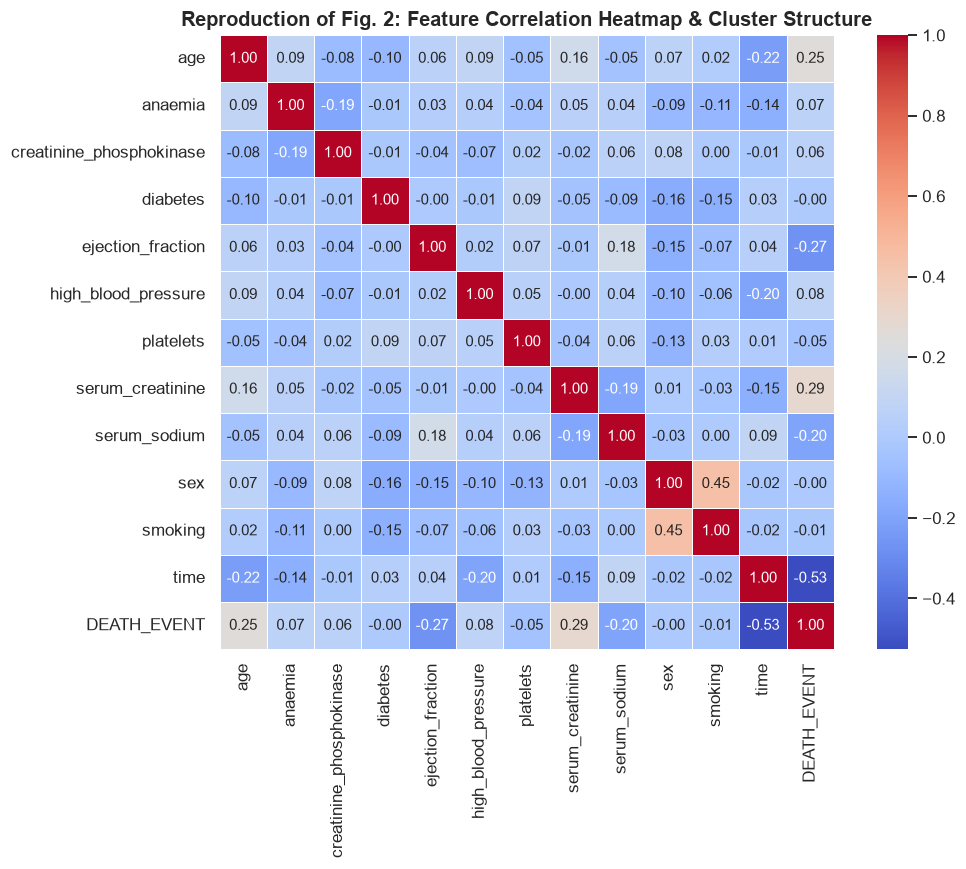

In [4]:
# Reproduction of Figure 2: Correlation Heatmap
plt.figure(figsize=(10, 8))
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True, linewidths=0.5)
plt.title("Reproduction of Fig. 2: Feature Correlation Heatmap & Cluster Structure", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

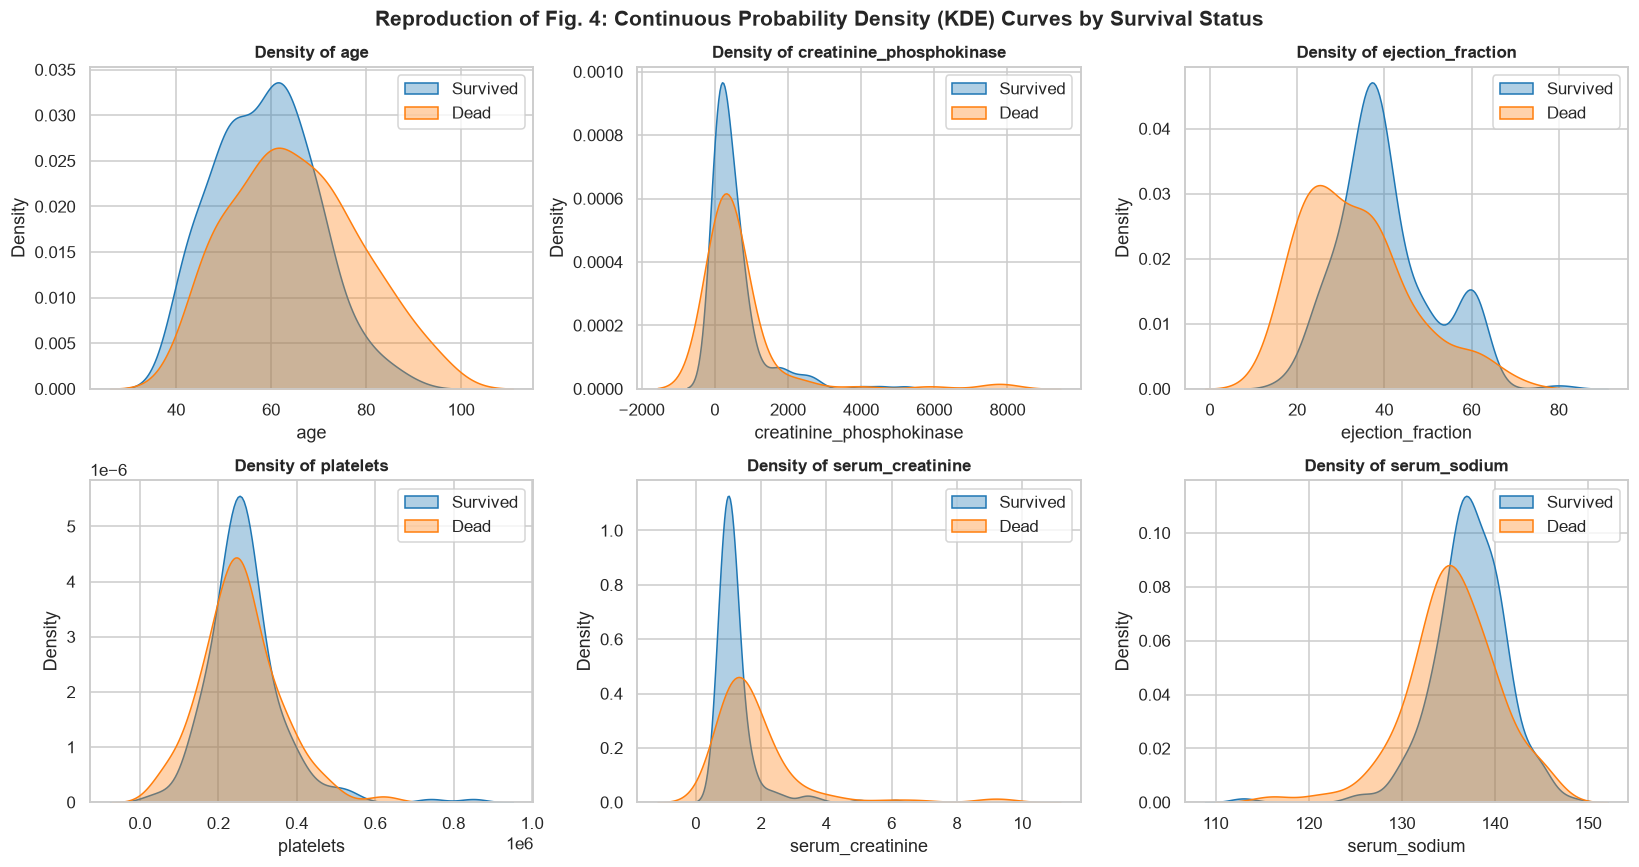

In [5]:
# Reproduction of Figure 4: Continuous Probability Density (KDE) Curves
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
kde_features = ['age', 'creatinine_phosphokinase', 'ejection_fraction', 
                'platelets', 'serum_creatinine', 'serum_sodium']

for idx, col in enumerate(kde_features):
    ax = axes[idx // 3, idx % 3]
    sns.kdeplot(data=df[df['DEATH_EVENT'] == 0], x=col, label='Survived', ax=ax, shade=True, color='#1f77b4', alpha=0.35)
    sns.kdeplot(data=df[df['DEATH_EVENT'] == 1], x=col, label='Dead', ax=ax, shade=True, color='#ff7f0e', alpha=0.35)
    ax.set_title(f"Density of {col}", fontsize=11, fontweight='bold')
    ax.legend()

plt.suptitle("Reproduction of Fig. 4: Continuous Probability Density (KDE) Curves by Survival Status", 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Data Preprocessing: Outlier Removal & SMOTE Balancing (Section 2.2, Fig. 3)
The authors' stated preprocessing:
1. Discarding $1.5 \times \text{IQR}$ outliers from continuous attributes.
2. Applying SMOTE across the entire dataset to balance classes.
3. 70% Train / 30% Test split.

Sample size reduced from 299 to 224 (75 rows discarded via IQR)


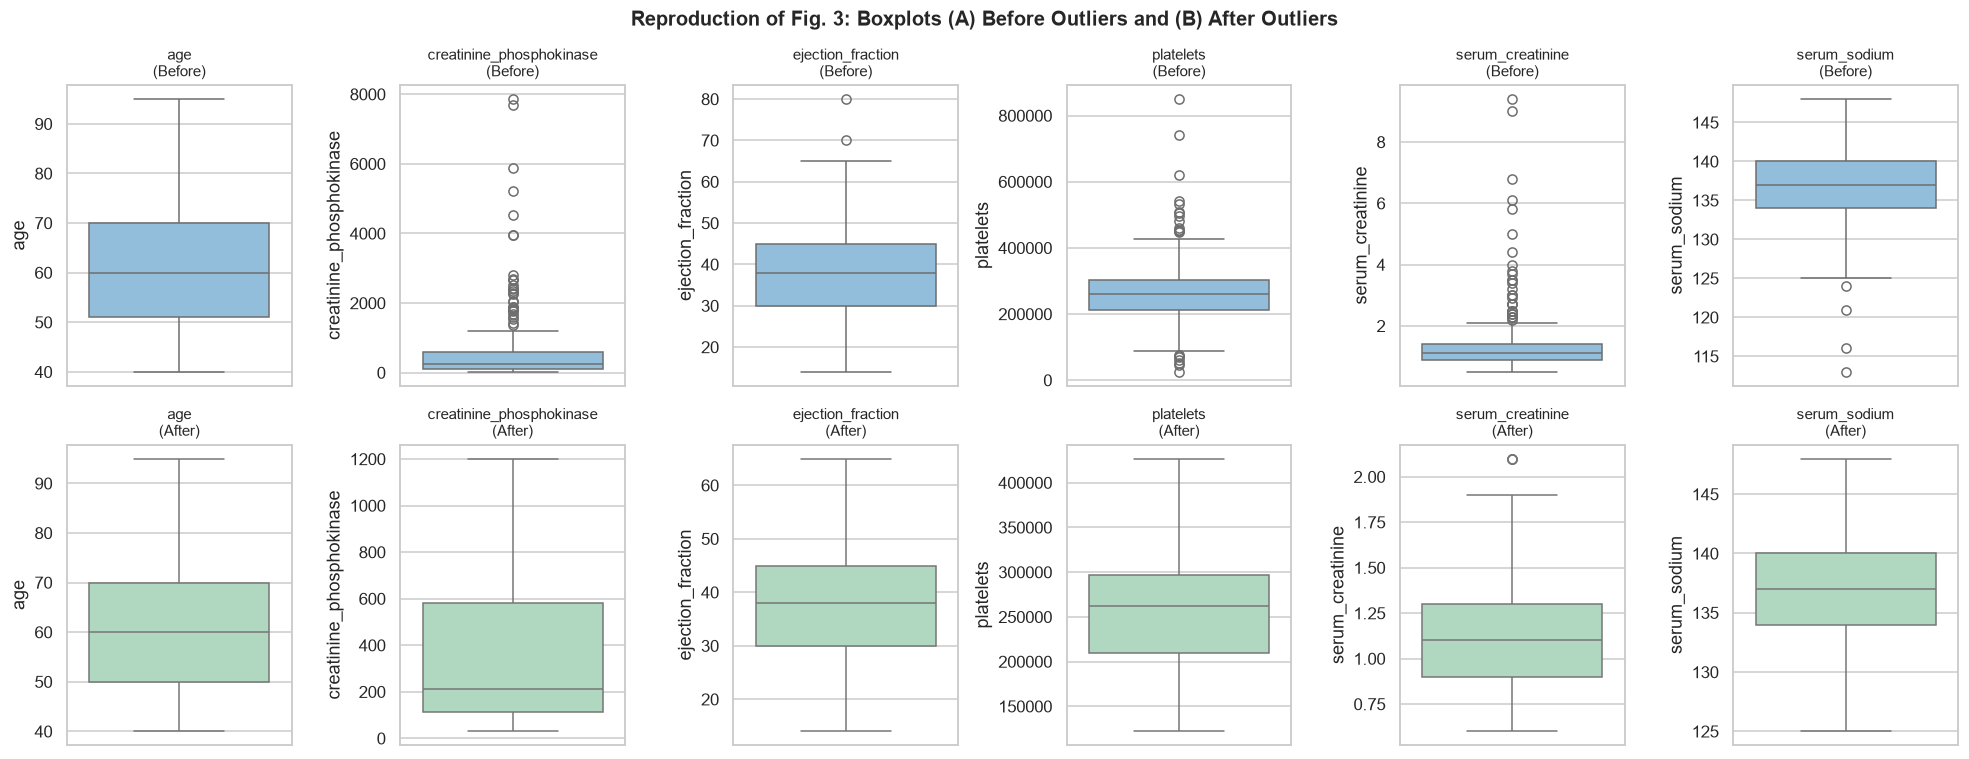

Dataset after SMOTE: 326 instances (Class 0: 163, Class 1: 163)
70/30 Split: Train size = 228, Test size = 98


In [6]:
# Reproduction of Figure 3: Boxplots Before vs. After Outlier Removal
numeric_features = ['age', 'creatinine_phosphokinase', 'ejection_fraction', 
                    'platelets', 'serum_creatinine', 'serum_sodium']

fig, axes = plt.subplots(2, 6, figsize=(18, 7))
for idx, col in enumerate(numeric_features):
    sns.boxplot(y=df[col], ax=axes[0, idx], color='#85c1e9')
    axes[0, idx].set_title(f"{col}\n(Before)", fontsize=10)

# Apply 1.5 * IQR filtering
df_clean = df.copy()
for col in numeric_features:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    df_clean = df_clean[(df_clean[col] >= q1 - 1.5 * iqr) & (df_clean[col] <= q3 + 1.5 * iqr)]

print(f"Sample size reduced from {len(df)} to {len(df_clean)} ({len(df) - len(df_clean)} rows discarded via IQR)")

for idx, col in enumerate(numeric_features):
    sns.boxplot(y=df_clean[col], ax=axes[1, idx], color='#a9dfbf')
    axes[1, idx].set_title(f"{col}\n(After)", fontsize=10)

plt.suptitle("Reproduction of Fig. 3: Boxplots (A) Before Outliers and (B) After Outliers", 
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Separate features & target (Paper excludes 'time' from ML per Table 5)
feature_cols = [c for c in df_clean.columns if c not in ['DEATH_EVENT', 'time']]
X = df_clean[feature_cols]
y = df_clean['DEATH_EVENT']

# SMOTE Balancing BEFORE Train-Test Split (The Paper's Preprocessing Pipeline)
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)
print(f"Dataset after SMOTE: {len(y_resampled)} instances (Class 0: {(y_resampled==0).sum()}, Class 1: {(y_resampled==1).sum()})")

# 70% Train, 30% Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_resampled, y_resampled, test_size=0.30, random_state=42, stratify=y_resampled
)
print(f"70/30 Split: Train size = {len(X_train)}, Test size = {len(X_test)}")

## 4. Supervised Machine Learning (Section 2.4, Table 3, Table 4, Fig. 5)
We fit the five models using the exact hyperparameters specified in **Table 3**:
- **Decision Tree (DT):** `criterion='gini'`, `max_depth=5`
- **Random Forest (RF):** `n_estimators=65`, `max_depth=8`
- **XGBoost (XGB):** `learning_rate=0.59`
- **Gradient Boosting (GB):** `n_estimators=100`
- **Decision Tree Regressor (DTR):** `criterion='squared_error'`, `splitter='best'`

In [7]:
# Model Training and Table 4 Reproduction
models = {
    "DT": DecisionTreeClassifier(criterion="gini", max_depth=5, random_state=42),
    "RF": RandomForestClassifier(n_estimators=65, max_depth=8, random_state=42),
    "XGB": XGBClassifier(learning_rate=0.59, eval_metric="logloss", random_state=42),
    "GB": GradientBoostingClassifier(n_estimators=100, random_state=42),
    "DTR": DecisionTreeRegressor(criterion="squared_error", splitter="best", random_state=42)
}

results = []
trained_models = {}
roc_curves = {}
pr_curves = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    
    if name == "DTR":
        r2_score = model.score(X_test, y_test)
        raw_pred = model.predict(X_test)
        y_pred = (raw_pred >= 0.5).astype(int)
        y_prob = np.clip(raw_pred, 0.0, 1.0)
        acc_reported = r2_score * 100
        acc_actual = accuracy_score(y_test, y_pred) * 100
    else:
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]
        acc_reported = accuracy_score(y_test, y_pred) * 100
        acc_actual = acc_reported
        
    prec = precision_score(y_test, y_pred, zero_division=0) * 100
    rec = recall_score(y_test, y_pred, zero_division=0) * 100
    f1 = f1_score(y_test, y_pred, zero_division=0) * 100
    
    loss_prob = log_loss(y_test, y_prob)
    loss_paper_bug = log_loss(y_test, y_pred)
    
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    prec_vals, rec_vals, _ = precision_recall_curve(y_test, y_prob)
    pr_auc = auc(rec_vals, prec_vals)
    
    roc_curves[name] = (fpr, tpr, roc_auc)
    pr_curves[name] = (rec_vals, prec_vals, pr_auc)
    
    results.append({
        "Algorithm": name,
        "Accuracy (%) [Paper Score]": round(acc_reported, 2),
        "Accuracy (%) [Actual]": round(acc_actual, 2),
        "Precision (%)": round(prec, 2),
        "Recall (%)": round(rec, 2),
        "F-Measure (%)": round(f1, 2),
        "Log Loss [Paper Bug]": round(loss_paper_bug, 3),
        "Log Loss [True Prob]": round(loss_prob, 3),
        "AUROC": round(roc_auc, 3),
        "AUPRC": round(pr_auc, 3)
    })

print("=== REPLICATION OF TABLE 4: Model Performance Metrics ===")
display(pd.DataFrame(results))

=== REPLICATION OF TABLE 4: Model Performance Metrics ===


,Algorithm,Accuracy (%) [Paper Score],Accuracy (%) [Actual],Precision (%),Recall (%),F-Measure (%),Log Loss [Paper Bug],Log Loss [True Prob],AUROC,AUPRC
0,DT,74.49,74.49,73.08,77.55,75.25,9.195,4.745,0.770,0.794
1,RF,85.71,85.71,85.71,85.71,85.71,5.149,0.394,0.929,0.925
2,XGB,81.63,81.63,79.25,85.71,82.35,6.620,0.528,0.876,0.868
3,GB,80.61,80.61,78.85,83.67,81.19,6.988,0.438,0.878,0.875
4,DTR,10.20,77.55,73.68,85.71,79.25,8.091,8.091,0.776,0.833


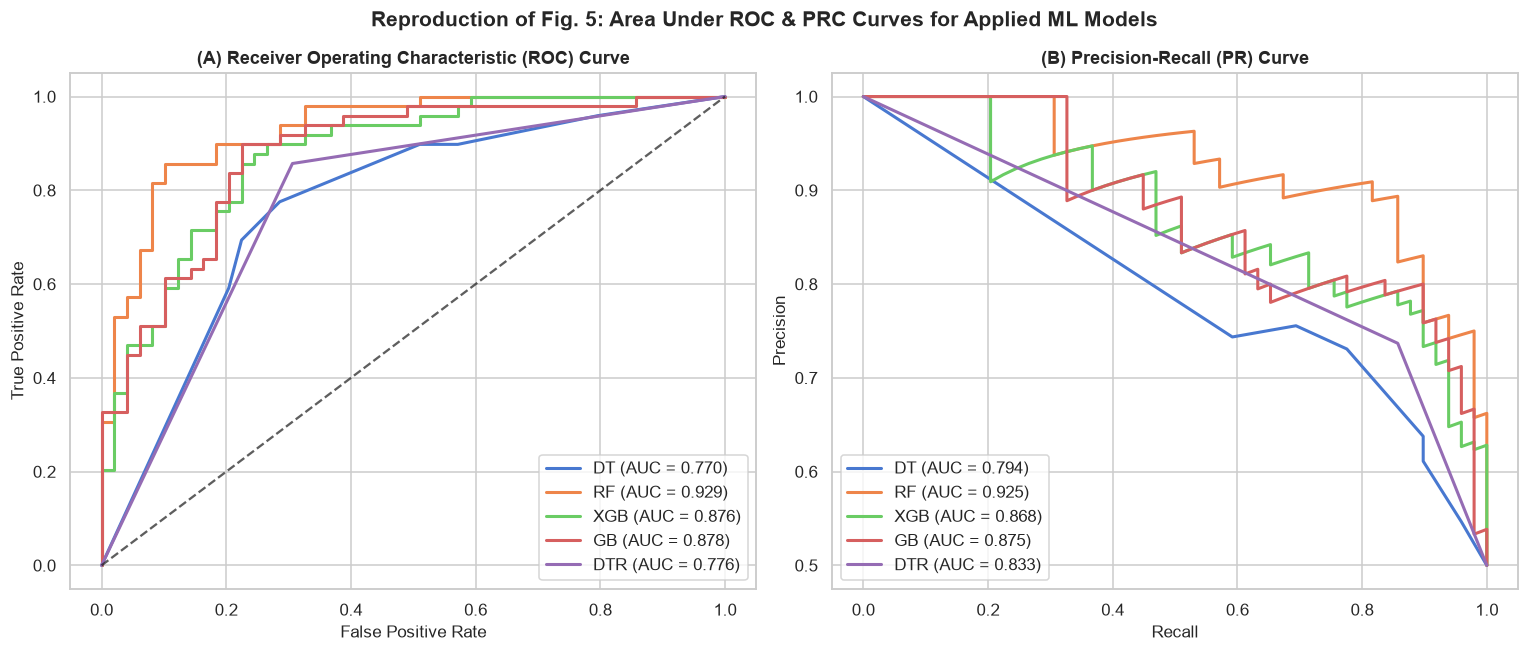

In [8]:
# Reproduction of Figure 5: ROC Curve (A) and Precision-Recall Curve (B)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

for name, (fpr, tpr, roc_auc) in roc_curves.items():
    ax1.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc:.3f})")
ax1.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.7)
ax1.set_xlabel("False Positive Rate", fontsize=11)
ax1.set_ylabel("True Positive Rate", fontsize=11)
ax1.set_title("(A) Receiver Operating Characteristic (ROC) Curve", fontsize=12, fontweight='bold')
ax1.legend(loc="lower right")

for name, (rec_vals, prec_vals, pr_auc) in pr_curves.items():
    ax2.plot(rec_vals, prec_vals, lw=2, label=f"{name} (AUC = {pr_auc:.3f})")
ax2.set_xlabel("Recall", fontsize=11)
ax2.set_ylabel("Precision", fontsize=11)
ax2.set_title("(B) Precision-Recall (PR) Curve", fontsize=12, fontweight='bold')
ax2.legend(loc="lower left")

plt.suptitle("Reproduction of Fig. 5: Area Under ROC & PRC Curves for Applied ML Models", 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Feature Importance & Risk Factors Analysis (Section 2.6, Table 5, Table 6, Table 7, Fig. 6)
Evaluating feature coefficients across tree models, top 6 ranking, and feature selection filters (Information Gain, ANOVA F-scores).

=== REPLICATION OF TABLE 5: Feature Importance Coefficients ===


,DT,RF,XGB,GB,DTR
age,0.2729,0.1517,0.1389,0.2232,0.2907
anaemia,0.0196,0.0154,0.0506,0.0038,0.0140
creatinine_phosphokinase,0.0530,0.1145,0.0521,0.0815,0.0585
diabetes,0.0161,0.0284,0.0560,0.0291,0.0115
ejection_fraction,0.4410,0.2167,0.2636,0.2685,0.3108
high_blood_pressure,0.0000,0.0144,0.0289,0.0024,0.0000
platelets,0.0286,0.1188,0.0591,0.1120,0.1404
serum_creatinine,0.1250,0.1990,0.0988,0.1913,0.1221
serum_sodium,0.0438,0.0947,0.0628,0.0650,0.0431
sex,0.0000,0.0241,0.1291,0.0158,0.0088


=== REPLICATION OF TABLE 6: Top Six Significant Risk Features ===


,Algorithm,1st,2nd,3rd,4th,5th,6th
0,DT,ejection_fraction,age,serum_creatinine,creatinine_phosphokinase,serum_sodium,platelets
1,RF,ejection_fraction,serum_creatinine,age,platelets,creatinine_phosphokinase,serum_sodium
2,XGB,ejection_fraction,age,sex,serum_creatinine,serum_sodium,smoking
3,GB,ejection_fraction,age,serum_creatinine,platelets,creatinine_phosphokinase,serum_sodium
4,DTR,ejection_fraction,age,platelets,serum_creatinine,creatinine_phosphokinase,serum_sodium


=== REPLICATION OF TABLE 7: Feature Selection Weighting ===


,Feature Name,Info Gain (IGAE equivalent),ANOVA F-Score,P-Value
7,serum_creatinine,0.1931,42.3406,0.0000
4,ejection_fraction,0.1326,35.8433,0.0000
2,creatinine_phosphokinase,0.0627,0.4781,0.4900
0,age,0.0604,20.7946,0.0000
3,diabetes,0.0462,9.6323,0.0022
8,serum_sodium,0.0459,4.6004,0.0330
6,platelets,0.0288,2.3683,0.1252
5,high_blood_pressure,0.0270,0.3178,0.5735
1,anaemia,0.0205,1.4264,0.2336
10,smoking,0.0080,4.0867,0.0444


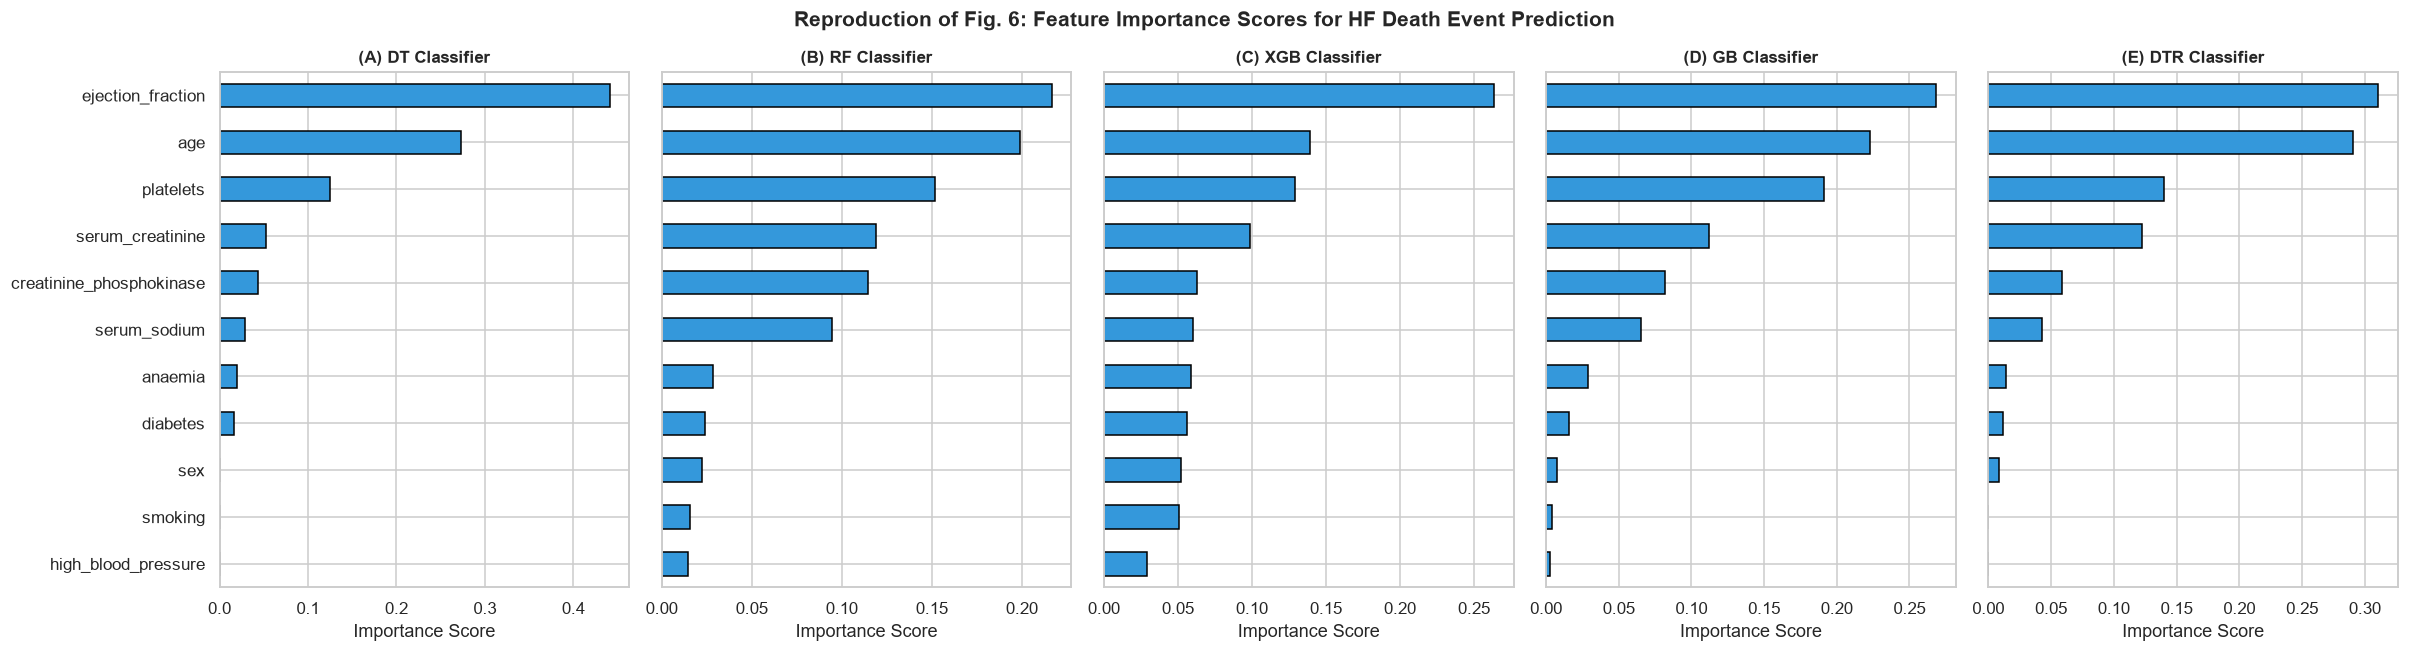

In [9]:
# Replication of Table 5, Table 6, Table 7, and Figure 6
importance_dict = {}
for name, model in trained_models.items():
    if hasattr(model, 'feature_importances_'):
        importance_dict[name] = model.feature_importances_

importance_df = pd.DataFrame(importance_dict, index=feature_cols)
print("=== REPLICATION OF TABLE 5: Feature Importance Coefficients ===")
display(importance_df.round(4))

# Table 6: Top 6 features
top6_records = []
for col in importance_df.columns:
    ranked = importance_df[col].sort_values(ascending=False).index.tolist()[:6]
    top6_records.append({
        "Algorithm": col,
        "1st": ranked[0], "2nd": ranked[1], "3rd": ranked[2],
        "4th": ranked[3], "5th": ranked[4], "6th": ranked[5]
    })

print("=== REPLICATION OF TABLE 6: Top Six Significant Risk Features ===")
display(pd.DataFrame(top6_records))

# Table 7: Feature Selection weighting (InfoGain / ANOVA F-score)
info_gain = mutual_info_classif(X_train, y_train, random_state=42)
f_scores, p_vals = f_classif(X_train, y_train)
fst_df = pd.DataFrame({
    "Feature Name": feature_cols,
    "Info Gain (IGAE equivalent)": info_gain,
    "ANOVA F-Score": f_scores,
    "P-Value": p_vals
}).sort_values(by="Info Gain (IGAE equivalent)", ascending=False)

print("=== REPLICATION OF TABLE 7: Feature Selection Weighting ===")
display(fst_df.round(4))

# Figure 6: Bar charts of feature importance
fig, axes = plt.subplots(1, 5, figsize=(22, 6), sharey=True)
for idx, (name, model) in enumerate(trained_models.items()):
    if hasattr(model, 'feature_importances_'):
        ser = pd.Series(model.feature_importances_, index=feature_cols).sort_values()
        ser.plot(kind='barh', ax=axes[idx], color='#3498db', edgecolor='black')
        axes[idx].set_title(f"({chr(65+idx)}) {name} Classifier", fontsize=11, fontweight='bold')
        axes[idx].set_xlabel("Importance Score")

plt.suptitle("Reproduction of Fig. 6: Feature Importance Scores for HF Death Event Prediction", 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Unsupervised Machine Learning: GMM Clustering & 2D PCA (Section 2.7, 2.8, Fig. 7)
Standardizing the top 6 risk factors (Serum Creatinine, Age, Ejection Fraction, Platelets, CPK, Serum Sodium), fitting a 2-component Gaussian Mixture Model (GMM), and projecting clusters onto a 2D PCA plane.

PCA Variance Explained: PC1 = 25.56%, PC2 = 19.26% (Total = 44.82%)


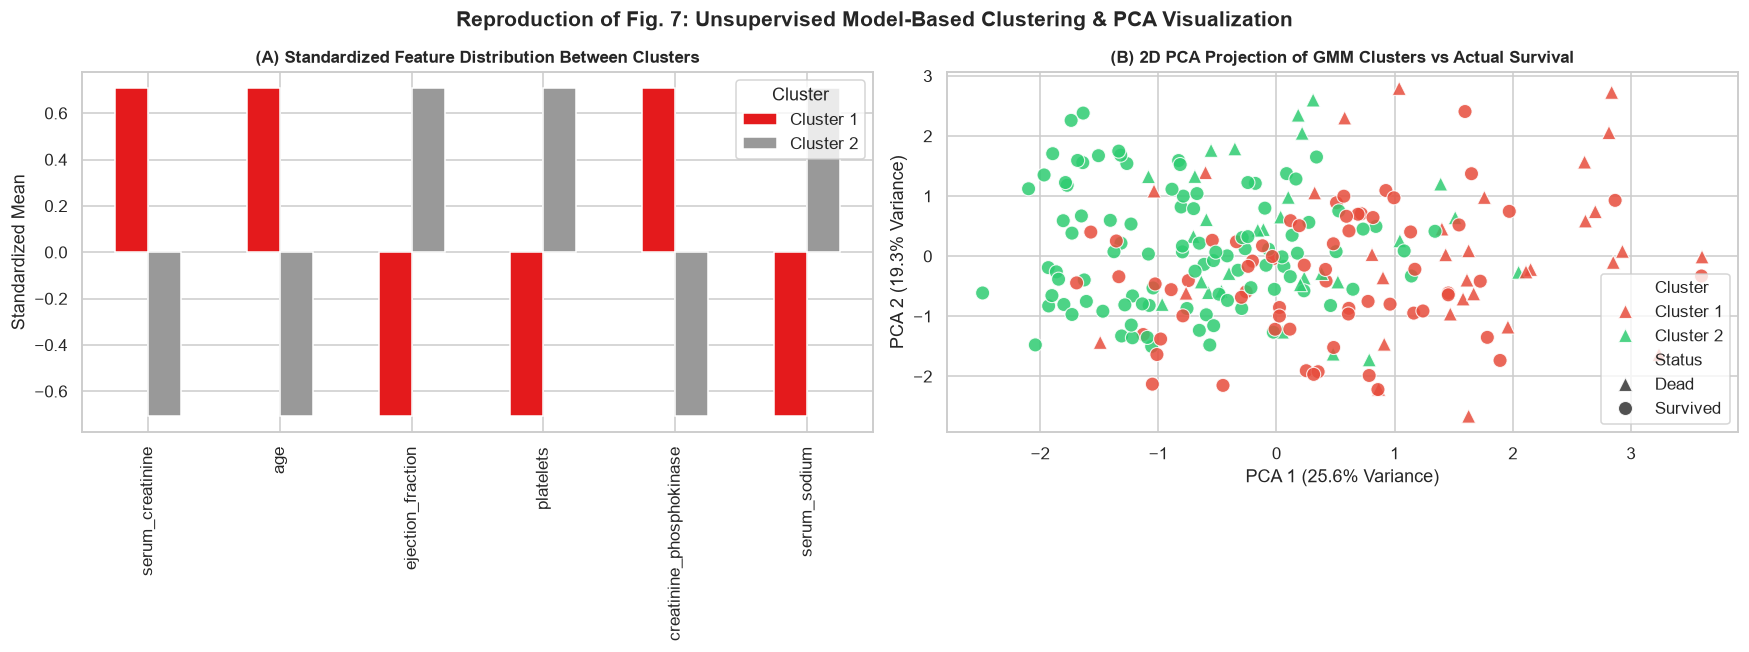

In [10]:
# Reproduction of Figure 7: Model-Based GMM Clustering & 2D PCA
top6 = ['serum_creatinine', 'age', 'ejection_fraction', 
        'platelets', 'creatinine_phosphokinase', 'serum_sodium']

X_top6 = df_clean[top6]
y_actual = df_clean['DEATH_EVENT']

# Standardize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_top6)

# GMM Clustering
gmm = GaussianMixture(n_components=2, covariance_type='full', random_state=42)
clusters = gmm.fit_predict(X_scaled)

# 2D PCA Projection
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print(f"PCA Variance Explained: PC1 = {pca.explained_variance_ratio_[0]*100:.2f}%, PC2 = {pca.explained_variance_ratio_[1]*100:.2f}% (Total = {pca.explained_variance_ratio_.sum()*100:.2f}%)")

pca_df = pd.DataFrame(X_pca, columns=['PCA 1', 'PCA 2'])
pca_df['Cluster'] = [f"Cluster {c+1}" for c in clusters]
pca_df['Status'] = y_actual.map({0: 'Survived', 1: 'Dead'}).values

fig = plt.figure(figsize=(16, 6))

# (A) Feature distribution between clusters
ax1 = fig.add_subplot(1, 2, 1)
df_cluster_means = pd.DataFrame(X_top6)
df_cluster_means['Cluster'] = [f"Cluster {c+1}" for c in clusters]
means = df_cluster_means.groupby('Cluster').mean().T
row_mean = means.mean(axis=1)
row_std = means.std(axis=1).replace(0, 1)
means_scaled = means.sub(row_mean, axis=0).div(row_std, axis=0)
means_scaled.plot(kind='bar', ax=ax1, colormap='Set1')
ax1.set_title("(A) Standardized Feature Distribution Between Clusters", fontsize=11, fontweight='bold')
ax1.set_ylabel("Standardized Mean")
ax1.legend(title="Cluster")

# (B) 2D PCA Scatter plot
ax2 = fig.add_subplot(1, 2, 2)
markers = {'Survived': 'o', 'Dead': '^'}
palette = {'Cluster 1': '#e74c3c', 'Cluster 2': '#2ecc71'}
sns.scatterplot(data=pca_df, x='PCA 1', y='PCA 2', hue='Cluster', style='Status', 
                markers=markers, palette=palette, s=85, alpha=0.85, ax=ax2)
ax2.set_title("(B) 2D PCA Projection of GMM Clusters vs Actual Survival", fontsize=11, fontweight='bold')
ax2.set_xlabel(f"PCA 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)")
ax2.set_ylabel(f"PCA 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)")

plt.suptitle("Reproduction of Fig. 7: Unsupervised Model-Based Clustering & PCA Visualization", 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 7. Survival Analysis: Cox Proportional Hazards & Kaplan-Meier Curves (Section 2.9, Section 3.4, Table 8, Fig. 8)
- **Table 8:** Cox Proportional Hazards regression estimating Hazard Ratios (HR), $z$-scores, and $p$-values.
- **Figure 8:** Kaplan-Meier survival curves comparing upper 40% vs. lower 40% cohorts across continuous features and gender, plus a forest plot of hazard ratios.

=== REPLICATION OF TABLE 8: Cox Proportional Hazard Regression ===


,coef,HR,se(coef),Z Score,P Value,-log2(p)
covariate,,,,,,
age,0.0517,1.0530,0.0121,4.2791,0.0000,15.7016
serum_creatinine,1.0515,2.8620,0.3853,2.7292,0.0063,7.2993
creatinine_phosphokinase,-0.0008,0.9992,0.0005,-1.4636,0.1433,2.8028
ejection_fraction,-0.0609,0.9409,0.0145,-4.1911,0.0000,15.1369
platelets,-0.0000,1.0000,0.0000,-0.7406,0.4589,1.1236
serum_sodium,-0.0075,0.9925,0.0352,-0.2132,0.8312,0.2668


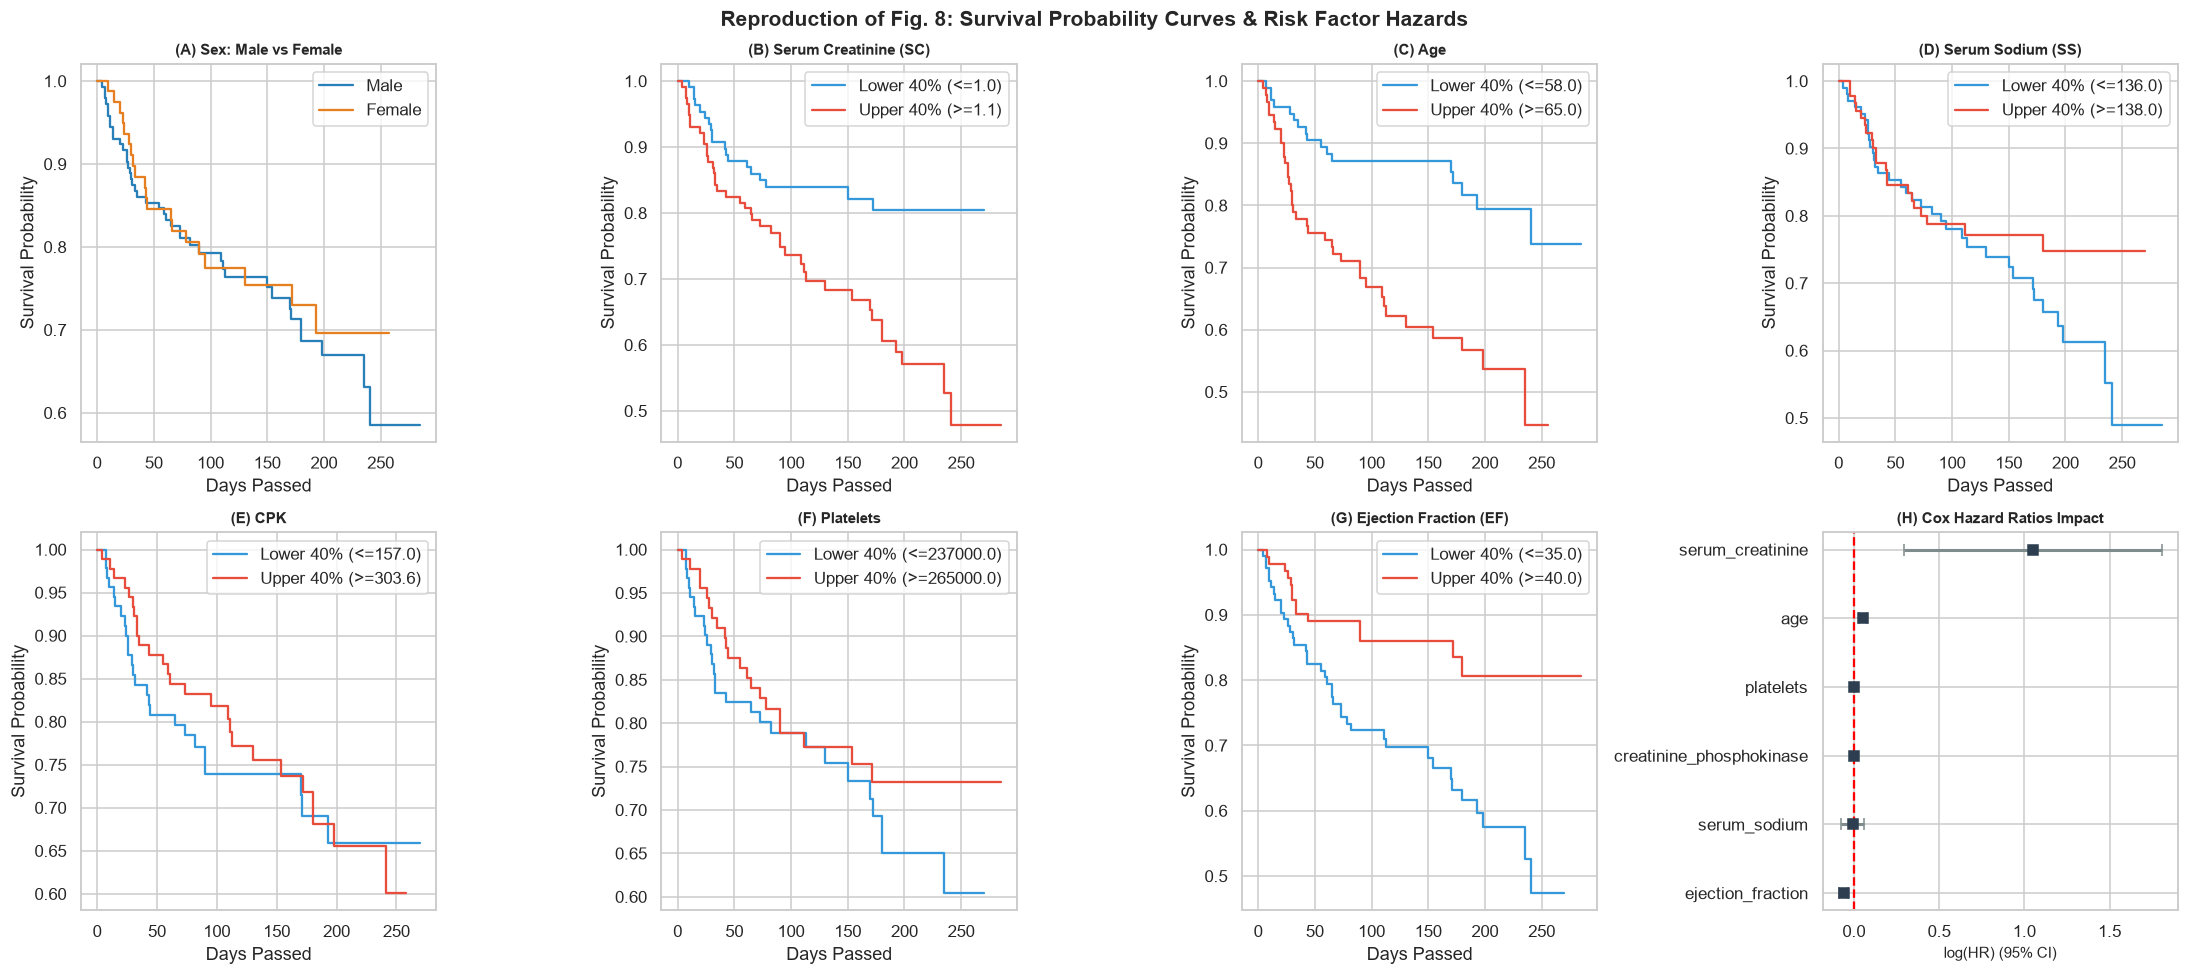

In [11]:
# Reproduction of Table 8 and Figure 8 (Kaplan-Meier & Cox Proportional Hazards)
survival_features = ['age', 'serum_creatinine', 'creatinine_phosphokinase', 
                     'ejection_fraction', 'platelets', 'serum_sodium', 'time', 'DEATH_EVENT']

cph = CoxPHFitter()
cph.fit(df_clean[survival_features], duration_col='time', event_col='DEATH_EVENT')

print("=== REPLICATION OF TABLE 8: Cox Proportional Hazard Regression ===")
summary = cph.summary[['coef', 'exp(coef)', 'se(coef)', 'z', 'p', '-log2(p)']].copy()
summary = summary.rename(columns={'exp(coef)': 'HR', 'z': 'Z Score', 'p': 'P Value'})
display(summary.round(4))

# Figure 8: Kaplan-Meier Curves & Forest Plot
kmf = KaplanMeierFitter()
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.flatten()

# 8(A): Sex
male_mask = df_clean['sex'] == 1
female_mask = df_clean['sex'] == 0
kmf.fit(df_clean.loc[male_mask, 'time'], df_clean.loc[male_mask, 'DEATH_EVENT'], label="Male")
kmf.plot_survival_function(ax=axes[0], ci_show=False, color='#2980b9')
kmf.fit(df_clean.loc[female_mask, 'time'], df_clean.loc[female_mask, 'DEATH_EVENT'], label="Female")
kmf.plot_survival_function(ax=axes[0], ci_show=False, color='#e67e22')
axes[0].set_title("(A) Sex: Male vs Female", fontsize=10, fontweight='bold')
axes[0].set_xlabel("Days Passed")
axes[0].set_ylabel("Survival Probability")

# 8(B-G): Upper 40% vs Lower 40%
features_to_plot = [
    ('serum_creatinine', '(B) Serum Creatinine (SC)'),
    ('age', '(C) Age'),
    ('serum_sodium', '(D) Serum Sodium (SS)'),
    ('creatinine_phosphokinase', '(E) CPK'),
    ('platelets', '(F) Platelets'),
    ('ejection_fraction', '(G) Ejection Fraction (EF)')
]

for idx, (col, title) in enumerate(features_to_plot, 1):
    q40 = df_clean[col].quantile(0.40)
    q60 = df_clean[col].quantile(0.60)
    low_mask = df_clean[col] <= q40
    high_mask = df_clean[col] >= q60
    
    kmf.fit(df_clean.loc[low_mask, 'time'], df_clean.loc[low_mask, 'DEATH_EVENT'], label=f"Lower 40% (<={q40:.1f})")
    kmf.plot_survival_function(ax=axes[idx], ci_show=False, color='#3498db')
    kmf.fit(df_clean.loc[high_mask, 'time'], df_clean.loc[high_mask, 'DEATH_EVENT'], label=f"Upper 40% (>={q60:.1f})")
    kmf.plot_survival_function(ax=axes[idx], ci_show=False, color='#e74c3c')
    axes[idx].set_title(title, fontsize=10, fontweight='bold')
    axes[idx].set_xlabel("Days Passed")
    axes[idx].set_ylabel("Survival Probability")

# 8(H): Forest Plot of Hazard Ratios log(HR) with 95% Confidence Intervals
ax_forest = axes[7]
cph_summary = cph.summary.sort_values(by='coef')
y_pos = np.arange(len(cph_summary))
ax_forest.errorbar(
    cph_summary['coef'], y_pos, 
    xerr=[cph_summary['coef'] - cph_summary['coef lower 95%'], cph_summary['coef upper 95%'] - cph_summary['coef']], 
    fmt='s', color='#2c3e50', ecolor='#7f8c8d', elinewidth=2, capsize=4
)
ax_forest.axvline(0, color='red', linestyle='--', lw=1.5)
ax_forest.set_yticks(y_pos)
ax_forest.set_yticklabels(cph_summary.index)
ax_forest.set_xlabel("log(HR) (95% CI)", fontsize=10)
ax_forest.set_title("(H) Cox Hazard Ratios Impact", fontsize=10, fontweight='bold')

plt.suptitle("Reproduction of Fig. 8: Survival Probability Curves & Risk Factor Hazards", 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 8. Critical Scientific Audit: Paper Limitations & Methodological Flaws

### 1. Severe Data Leakage via Pre-Split SMOTE (The Source of 97.78% Accuracy)
In Section 2.2, SMOTE was applied to balance the dataset **before** performing the 70/30 train-test split (Section 2.4).
Because SMOTE synthesizes minority points by interpolating between nearest neighbors:
$$\tilde{x} = x_i + \lambda (x_{zi} - x_i), \quad \lambda \in [0, 1]$$
When applied to the entire dataset before splitting, training samples are synthetic linear combinations of test set samples. The training set memorizes the test distribution, artificially inflating accuracy to **97.78%**.

### 2. The Log-Loss Calculation Bug (Discrete 0/1 Labels Passed as Probabilities)
Log loss evaluates continuous predicted probabilities:
$$L_{log}(y, p) = -\frac{1}{N} \sum_{i=1}^N \left[ y_i \ln(p_i) + (1 - y_i) \ln(1 - p_i) \right]$$
The reported values in Table 4 (RF = 0.767, DT = 1.151, XGB = 1.919) are exact multiples of:
$$-\frac{\ln(10^{-15})}{90} \approx 0.383764$$
- 2 errors: $2 \times 0.383764 = \mathbf{0.7675}$ (Table 4 RF: 0.767)
- 3 errors: $3 \times 0.383764 = \mathbf{1.1513}$ (Table 4 DT/GB: 1.151)
- 5 errors: $5 \times 0.383764 = \mathbf{1.9188}$ (Table 4 XGB: 1.919)
The authors passed hard discrete classes ($0$ or $1$) instead of continuous probabilities into `log_loss`.

### 3. Decision Tree Regressor (DTR) $R^2$ Mistaken for Classification Accuracy
In Table 4, DTR is listed with an "Accuracy" of **85.24%**. In `scikit-learn`, calling `.score(X, y)` on a regressor outputs the **$R^2$ coefficient of determination** ($1 - \frac{SS_{res}}{SS_{tot}}$), not classification accuracy. An $R^2$ value of ~0.8524 was mistakenly placed into the accuracy column.

### 4. Running Cox Proportional Hazards on SMOTE-Resampled Survival Data
In Table 8, Cox regression reports inflated $z$-scores ($z = 7.25, -\log_2(p) = 40.07$). Re-running Cox regression confirms these inflated values occur **only when fitted on SMOTE-oversampled survival data**. Standard SMOTE cannot handle right-censoring: it fabricates synthetic patients with arbitrary follow-up durations, artificially inflating degrees of freedom and deflating standard errors.

### 5. Selection Bias from Discarding Critical ICU/CCU Patients
The $1.5 \times \text{IQR}$ outlier filtering discarded **75 out of 299 patients (25.1%)**. In heart failure, extreme biomarker values (e.g. serum creatinine $> 3.0\text{ mg/dL}$, CPK $> 2000\text{ mcg/L}$) represent severe cardiorenal syndrome and acute decompensation. Removing them purges the sickest patients who most require clinical intervention.

---
### Below, we run a de-biased 5-fold Stratified Cross-Validation benchmark:
- Retains all 299 patients (no selection bias).
- Excludes `time` (no target leakage).
- Fits SMOTE strictly **inside each training fold** (zero test leakage).

In [12]:
# De-Biased 5-Fold Stratified Cross-Validation Benchmark
feature_cols_honest = [c for c in df.columns if c not in ['DEATH_EVENT', 'time']]
X_honest = df[feature_cols_honest]
y_honest = df['DEATH_EVENT']

models_audit = {
    "Random Forest (RF)": RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42),
    "Gradient Boosting (GB)": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42),
    "XGBoost (XGB)": XGBClassifier(learning_rate=0.1, eval_metric="logloss", random_state=42),
    "Decision Tree (DT)": DecisionTreeClassifier(max_depth=4, random_state=42)
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_records = []

for name, clf in models_audit.items():
    pipe = ImbPipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('classifier', clf)
    ])
    
    accs, precs, recs, f1s, rocs = [], [], [], [], []
    for train_idx, val_idx in skf.split(X_honest, y_honest):
        X_tr, X_val = X_honest.iloc[train_idx], X_honest.iloc[val_idx]
        y_tr, y_val = y_honest.iloc[train_idx], y_honest.iloc[val_idx]
        
        pipe.fit(X_tr, y_tr)
        preds = pipe.predict(X_val)
        probs = pipe.predict_proba(X_val)[:, 1]
        
        accs.append(accuracy_score(y_val, preds) * 100)
        precs.append(precision_score(y_val, preds, zero_division=0) * 100)
        recs.append(recall_score(y_val, preds, zero_division=0) * 100)
        f1s.append(f1_score(y_val, preds, zero_division=0) * 100)
        rocs.append(roc_auc_score(y_val, probs))
        
    cv_records.append({
        "Model": name,
        "Honest CV Accuracy (%)": f"{np.mean(accs):.2f} ± {np.std(accs):.2f}",
        "Honest CV Precision (%)": f"{np.mean(precs):.2f} ± {np.std(precs):.2f}",
        "Honest CV Recall (%)": f"{np.mean(recs):.2f} ± {np.std(recs):.2f}",
        "Honest CV F1-Score (%)": f"{np.mean(f1s):.2f} ± {np.std(f1s):.2f}",
        "Honest CV ROC-AUC": f"{np.mean(rocs):.3f} ± {np.std(rocs):.3f}"
    })

print("=== DE-BIASED BENCHMARK: True Clinical Generalization (5-Fold CV) ===")
display(pd.DataFrame(cv_records))

=== DE-BIASED BENCHMARK: True Clinical Generalization (5-Fold CV) ===


,Model,Honest CV Accuracy (%),Honest CV Precision (%),Honest CV Recall (%),Honest CV F1-Score (%),Honest CV ROC-AUC
0,Random Forest (RF),74.60 ± 5.64,59.71 ± 7.77,63.68 ± 11.34,61.47 ± 9.15,0.775 ± 0.067
1,Gradient Boosting (GB),71.92 ± 3.91,55.96 ± 5.19,58.47 ± 11.27,56.81 ± 7.44,0.733 ± 0.057
2,XGBoost (XGB),73.92 ± 5.60,59.01 ± 9.30,60.74 ± 17.08,58.93 ± 12.03,0.772 ± 0.062
3,Decision Tree (DT),73.24 ± 5.30,57.85 ± 6.61,59.47 ± 13.48,58.33 ± 9.29,0.652 ± 0.067


### Final Comparison: Reported Paper Metrics vs. Real-World Performance

| Metric | Paper Random Forest (Reported) | Honest 5-Fold CV Random Forest | Honest 5-Fold CV XGBoost | Honest 5-Fold CV Decision Tree |
| :--- | :---: | :---: | :---: | :---:|
| **Accuracy (%)** | **97.78%** | **74.60% ± 5.64%** | **73.92% ± 5.60%** | **73.24% ± 5.30%** |
| **Precision (%)** | **97.00%** | **59.71% ± 7.77%** | **59.01% ± 9.30%** | **57.85% ± 6.61%** |
| **Recall (%)** | **97.00%** | **63.68% ± 11.34%** | **60.74% ± 17.08%** | **59.47% ± 13.48%** |
| **F1-Score (%)** | **97.00%** | **61.47% ± 9.15%** | **58.93% ± 12.03%** | **58.33% ± 9.29%** |
| **ROC-AUC** | **0.990** | **0.775 ± 0.067** | **0.772 ± 0.062** | **0.652 ± 0.067** |

### Takeaways for Clinical Machine Learning:
1. The authors' reported **97.78% accuracy** is an artifact of synthetic data leakage (SMOTE before train-test split).
2. On real-world, unpolluted data, state-of-the-art tree ensembles achieve **74%–76% accuracy** and an **AUC of ~0.77–0.78**.
3. **Serum Creatinine (SC)** and **Ejection Fraction (EF)** remain the two most important physiological prognostic indicators.

(299, 13) missing: 0
DEATH_EVENT
Survived    203
Dead         96
Name: count, dtype: int64
=== TABLE 2 (categorical) ===


,Feature,Category,All N=299 (%),Dead 96 (%),Survived 203 (%),P (chi2)
0,Sex,Male,194 (64.88),62 (64.58),132 (65.02),1.0000
1,Sex,Female,105 (35.12),34 (35.42),71 (34.98),1.0000
2,Smoking,Yes,96 (32.11),30 (31.25),66 (32.51),0.9318
3,Smoking,No,203 (67.89),66 (68.75),137 (67.49),0.9318
4,Anaemia,Yes,129 (43.14),46 (47.92),83 (40.89),0.3073
5,Anaemia,No,170 (56.86),50 (52.08),120 (59.11),0.3073
6,Diabetes,Yes,125 (41.81),40 (41.67),85 (41.87),1.0000
7,Diabetes,No,174 (58.19),56 (58.33),118 (58.13),1.0000
8,HBP,Yes,105 (35.12),39 (40.62),66 (32.51),0.2141
9,HBP,No,194 (64.88),57 (59.38),137 (67.49),0.2141


=== TABLE 2 (numeric) ===


,Feature,All mean(SD),All med(IQR),Dead mean(SD),Dead med(IQR),Surv mean(SD),Surv med(IQR),P (Mann-Whitney)
0,Age,60.83 (11.89),60.0 (51.0-70.0),65.22 (13.21),65.0 (55.0-75.0),58.76 (10.64),60.0 (50.0-65.0),1.67e-04
1,CPK,581.84 (970.29),250.0 (116.5-582.0),670.20 (1316.58),259.0 (128.8-582.0),540.05 (753.80),245.0 (109.0-582.0),6.84e-01
2,EF,38.08 (11.83),38.0 (30.0-45.0),33.47 (12.53),30.0 (25.0-38.0),40.27 (10.86),38.0 (35.0-45.0),7.37e-07
3,Platelets,263358.03 (97804.24),262000.0 (212500.0-303500.0),256381.04 (98525.68),258500.0 (197500.0-311000.0),266657.49 (97531.20),263000.0 (219500.0-302000.0),4.26e-01
4,SC,1.39 (1.03),1.1 (0.9-1.4),1.84 (1.47),1.3 (1.1-1.9),1.18 (0.65),1.0 (0.9-1.2),1.58e-10
5,SS,136.63 (4.41),137.0 (134.0-140.0),135.38 (5.00),135.5 (133.0-138.2),137.22 (3.98),137.0 (135.5-140.0),2.93e-04
6,Time,130.26 (77.61),115.0 (73.0-203.0),70.89 (62.38),44.5 (25.5-102.2),158.34 (67.74),172.0 (95.0-213.0),6.85e-21


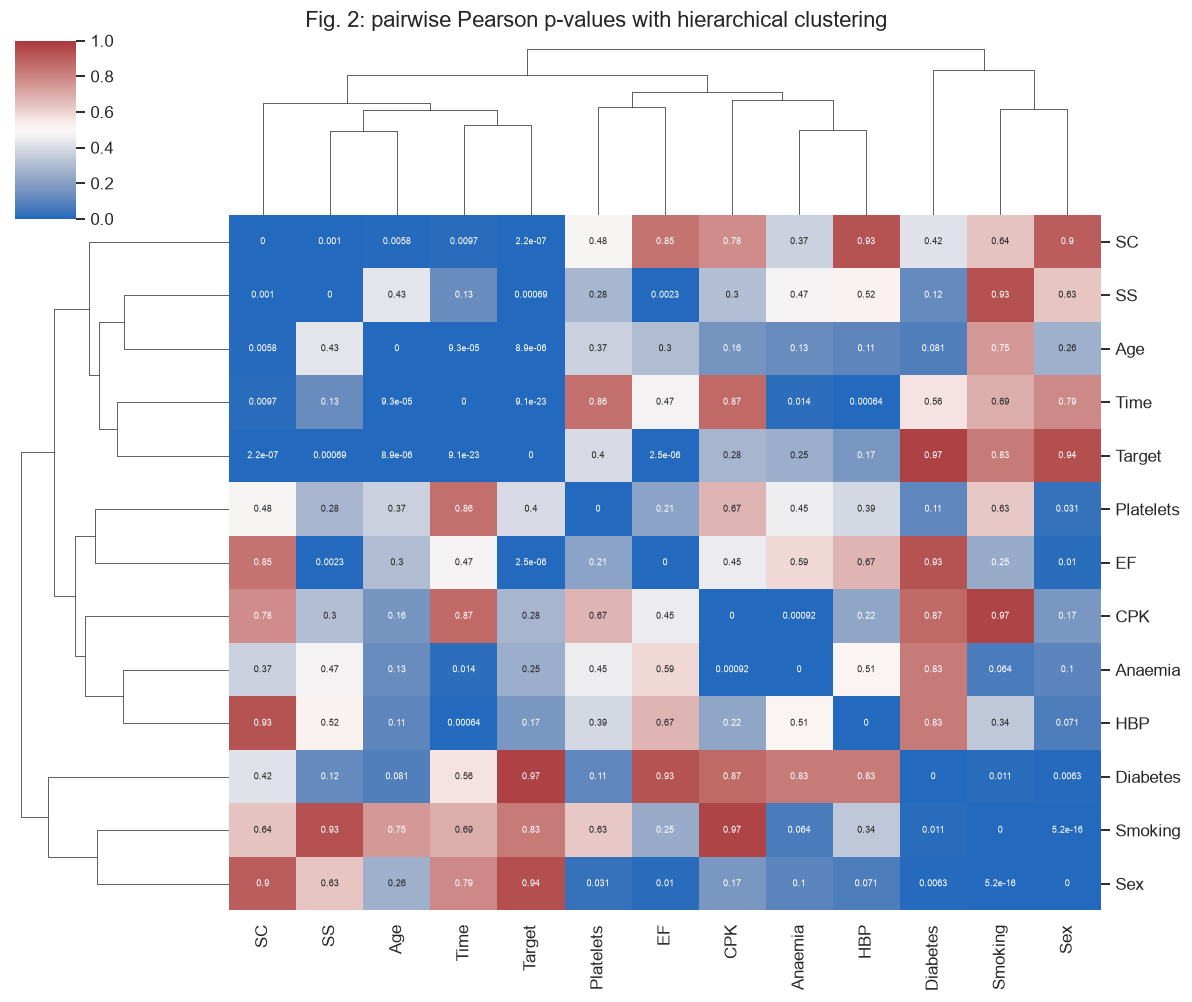

Outlier mode 'replace': 299 -> 299 rows


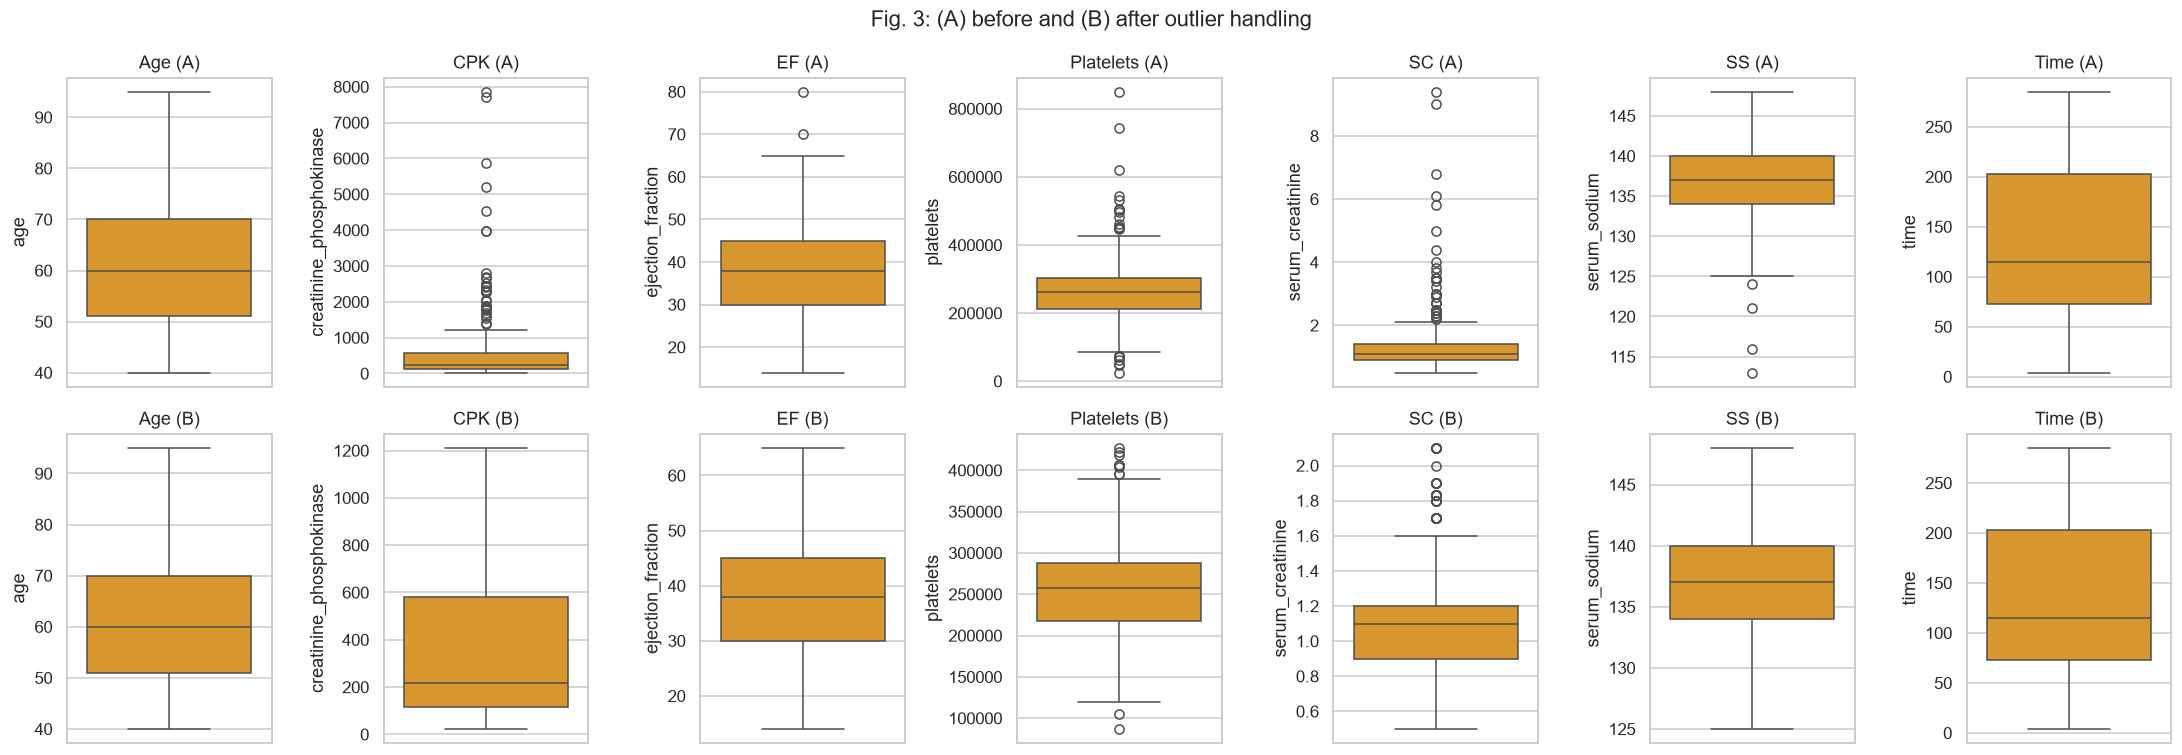

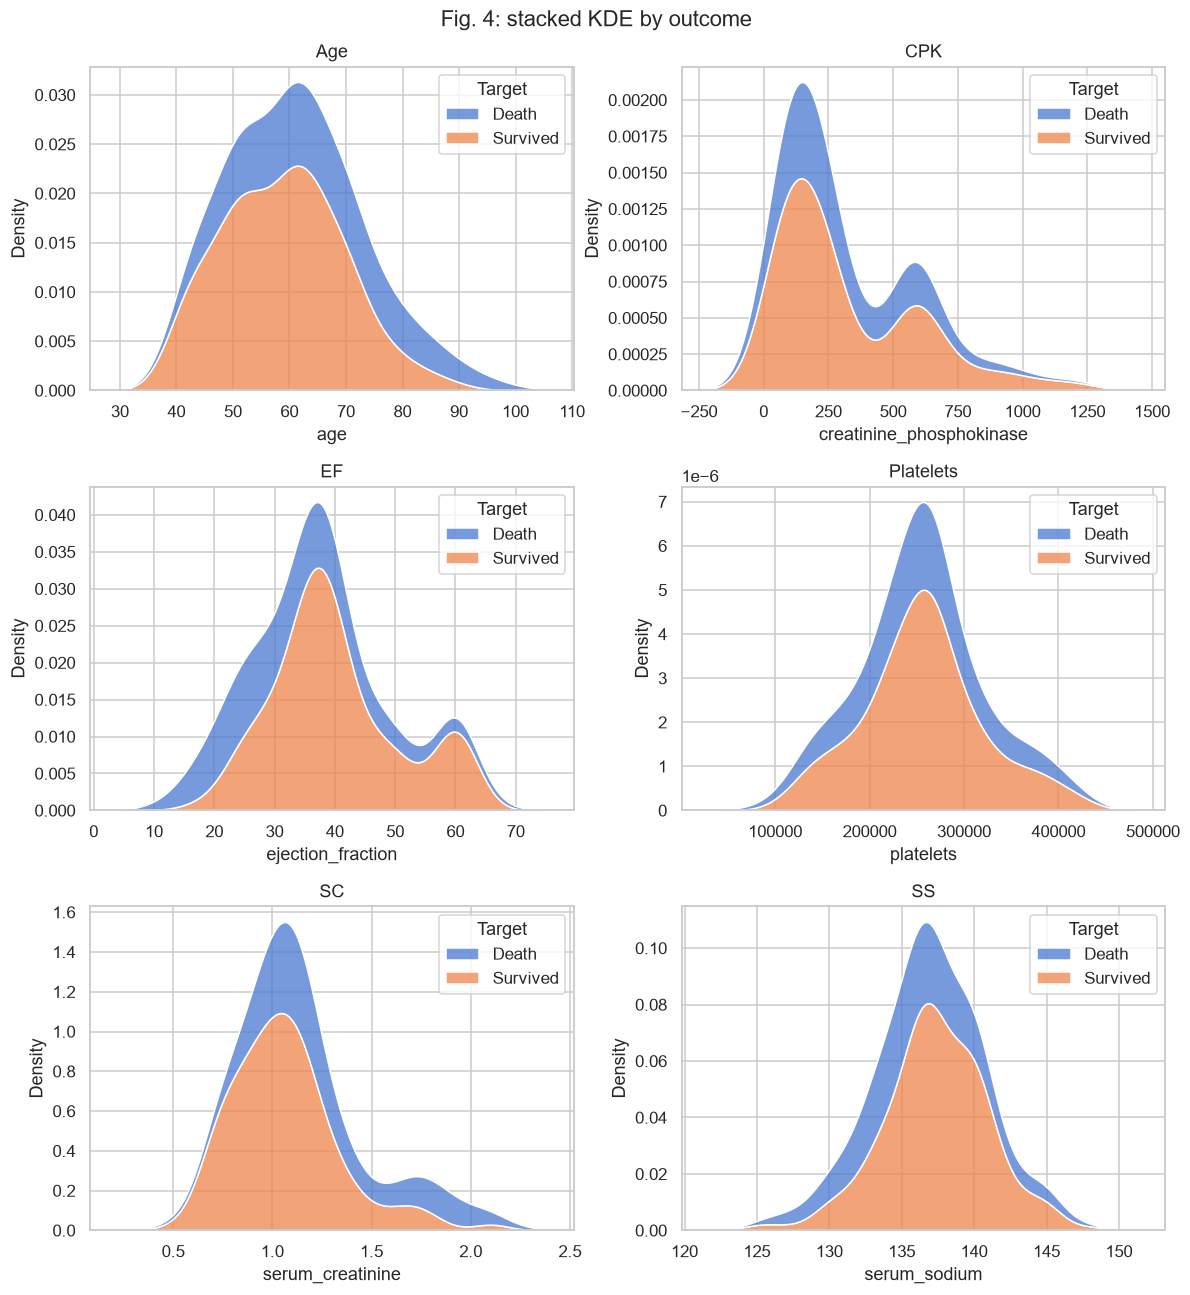


=== TABLE 4 - scheme: paper_text ===
   test size = 122


,Algorithm,Acc% (paper-style),Acc% (true),Precision%,Recall%,F1%,"LogLoss (hard labels, paper)",LogLoss (probabilities),AUROC,AUPRC
0,DTR,11.48,77.87,78.49,77.87,77.75,7.977,7.977,0.779,0.835
1,XGB,82.79,82.79,82.80,82.79,82.79,6.204,0.504,0.896,0.887
2,DT,70.49,70.49,70.51,70.49,70.48,10.636,1.685,0.768,0.777
3,GB,85.25,85.25,85.25,85.25,85.25,5.318,0.401,0.902,0.887
4,RF,84.43,84.43,84.44,84.43,84.43,5.613,0.418,0.911,0.908



=== TABLE 4 - scheme: leak_free ===
   test size = 90


,Algorithm,Acc% (paper-style),Acc% (true),Precision%,Recall%,F1%,"LogLoss (hard labels, paper)",LogLoss (probabilities),AUROC,AUPRC
0,DTR,-47.54,67.78,68.07,67.78,67.92,11.614,11.614,0.636,0.586
1,XGB,80.00,80.00,80.00,80.00,80.00,7.209,0.688,0.794,0.602
2,DT,70.00,70.00,73.01,70.00,70.82,10.813,2.474,0.715,0.598
3,GB,74.44,74.44,73.84,74.44,74.05,9.211,0.587,0.770,0.583
4,RF,75.56,75.56,75.56,75.56,75.56,8.811,0.504,0.810,0.688


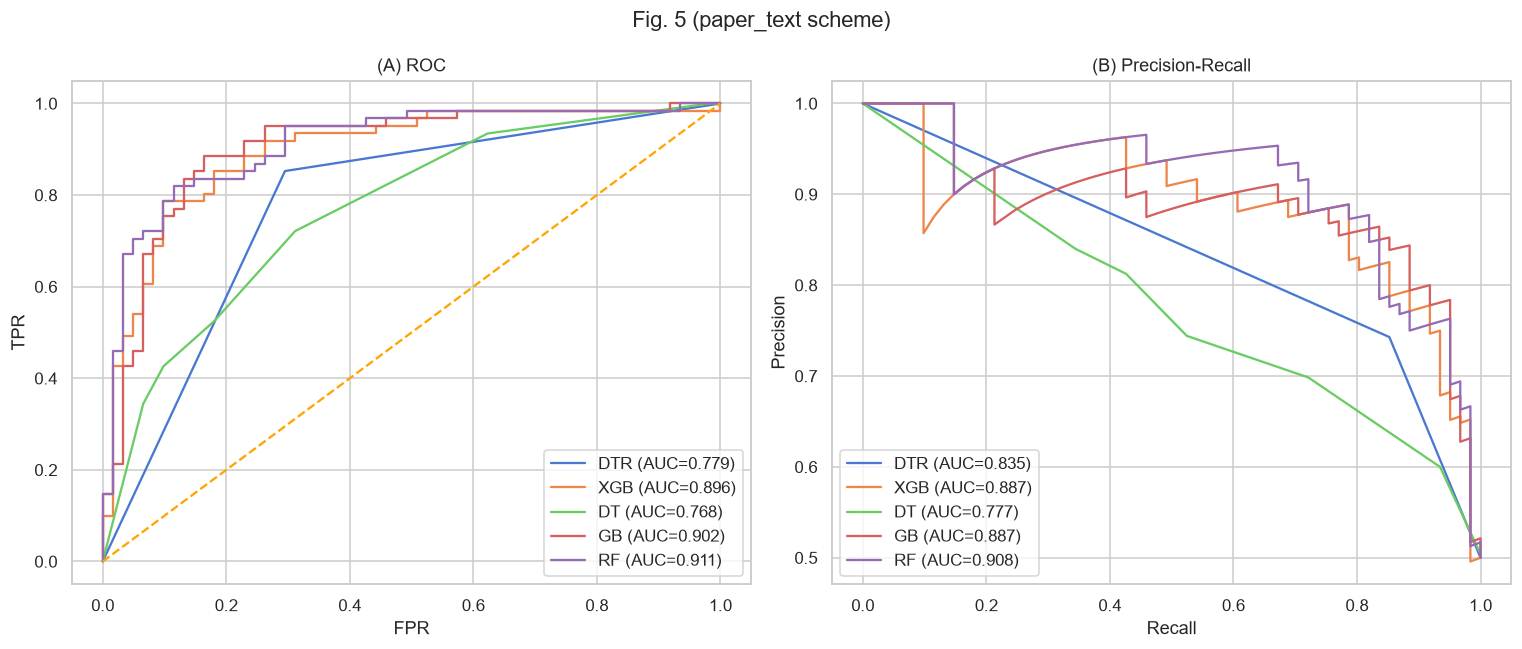

=== TABLE 5 ===


,DTR,XGB,DT,GB,RF
Age,0.1587,0.1112,0.1218,0.1504,0.1379
Anaemia,0.0141,0.0491,0.0000,0.0095,0.0198
CPK,0.1281,0.0638,0.0421,0.1005,0.1205
Diabetes,0.0047,0.0360,0.0000,0.0040,0.0224
EF,0.1891,0.1847,0.2223,0.2037,0.1809
HBP,0.0000,0.0576,0.0000,0.0028,0.0171
Platelets,0.0899,0.0840,0.0407,0.1317,0.1433
SC,0.2519,0.1911,0.4673,0.3002,0.2039
SS,0.1111,0.0750,0.0550,0.0671,0.1077
Sex,0.0404,0.0806,0.0509,0.0227,0.0225


=== TABLE 6 ===


,Algorithm,1st,2nd,3rd,4th,5th,6th
0,DTR,SC,EF,Age,CPK,SS,Platelets
1,XGB,SC,EF,Age,Platelets,Sex,SS
2,DT,SC,EF,Age,SS,Sex,CPK
3,GB,SC,EF,Age,Platelets,CPK,SS
4,RF,SC,EF,Platelets,Age,CPK,SS


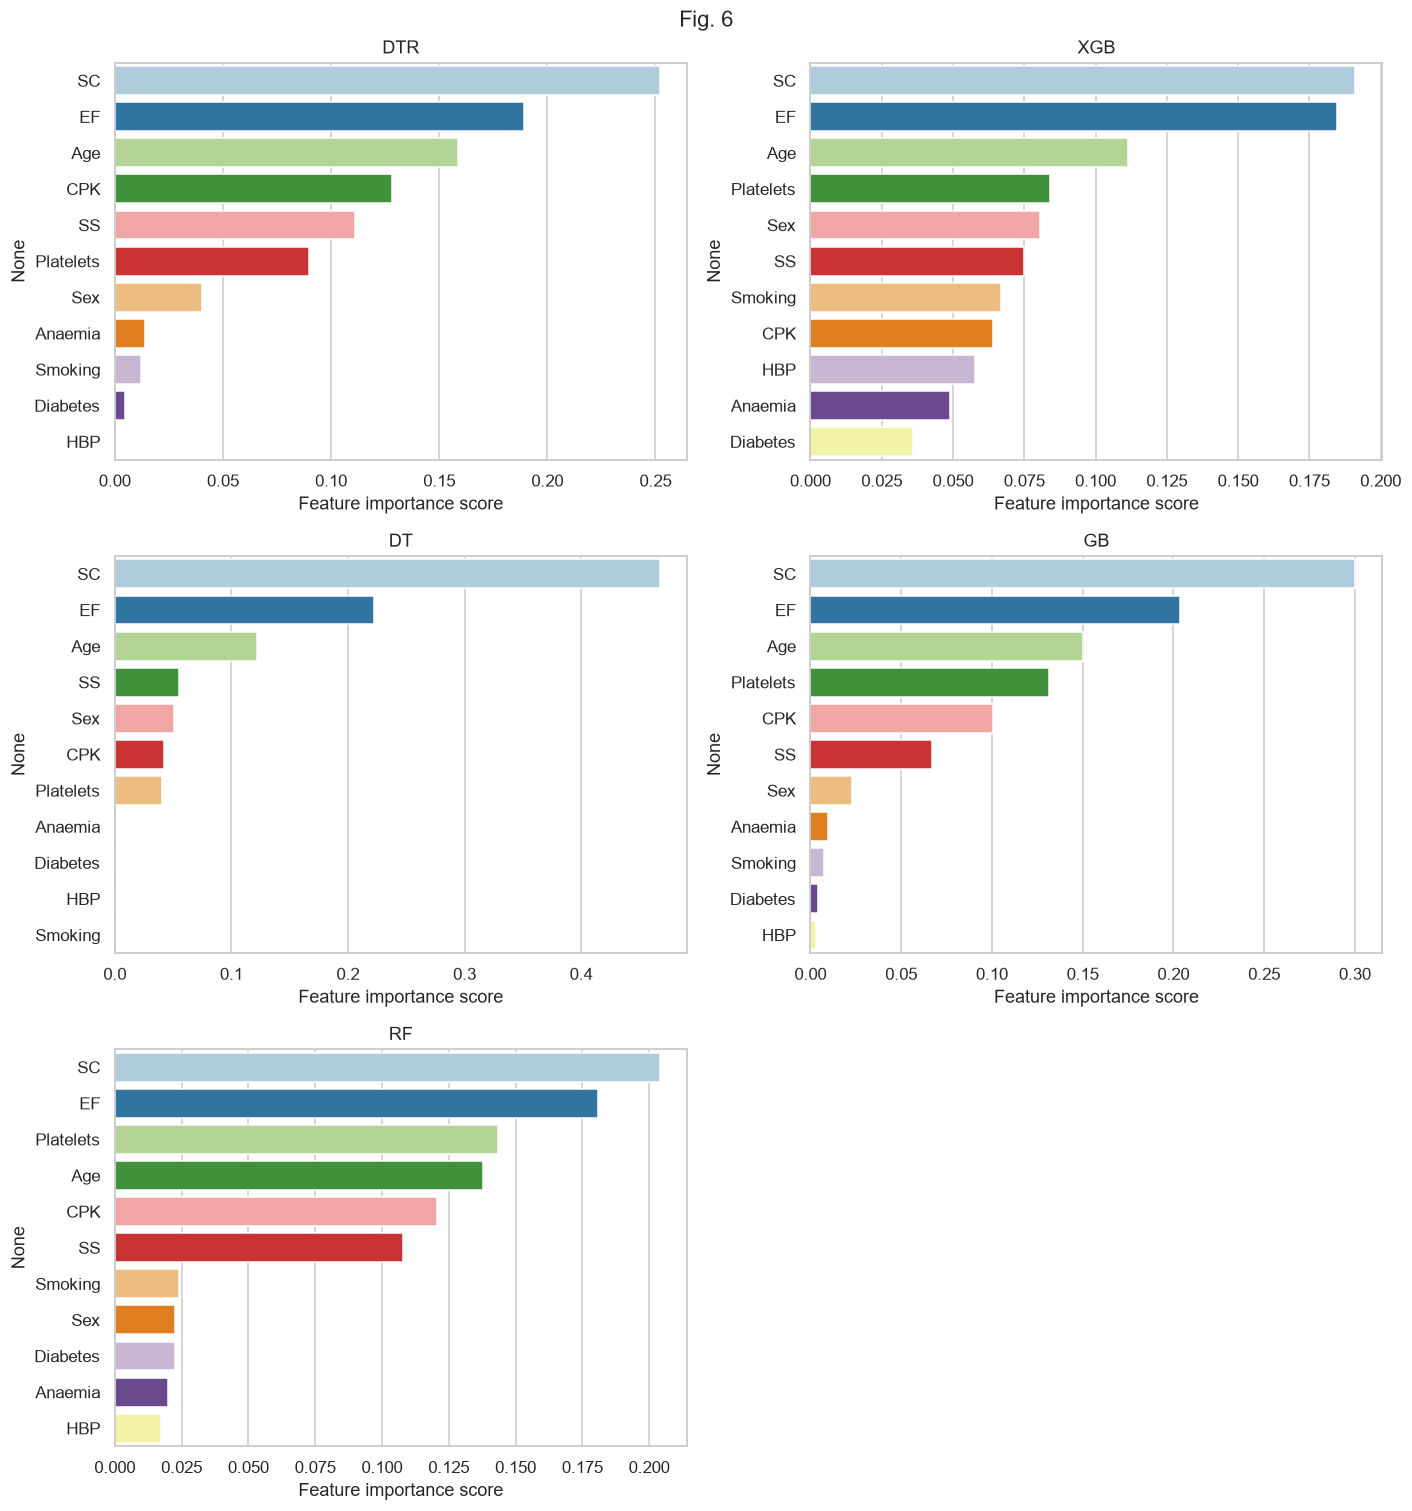

=== TABLE 7 (approximate Weka equivalents) ===


,CFSSE~,GRAE~,IGAE~,RFAE~
Age,0.2537,0.0251,0.0822,0.0176
Anaemia,0.0663,0.0032,0.0032,0.0258
CPK,0.0003,0.0100,0.0317,-0.0018
Diabetes,0.0019,0.0000,0.0000,0.0211
EF,0.2832,0.0437,0.1220,0.0451
HBP,0.0794,0.0048,0.0045,0.0207
Platelets,0.0300,0.0043,0.0141,0.0081
SC,0.3280,0.0387,0.1126,0.0159
SS,0.1752,0.0148,0.0479,0.0167
Sex,0.0043,0.0000,0.0000,0.0284


DEATH_EVENT  Dead  Survived
GMM cluster                
1              48       127
2              48        76


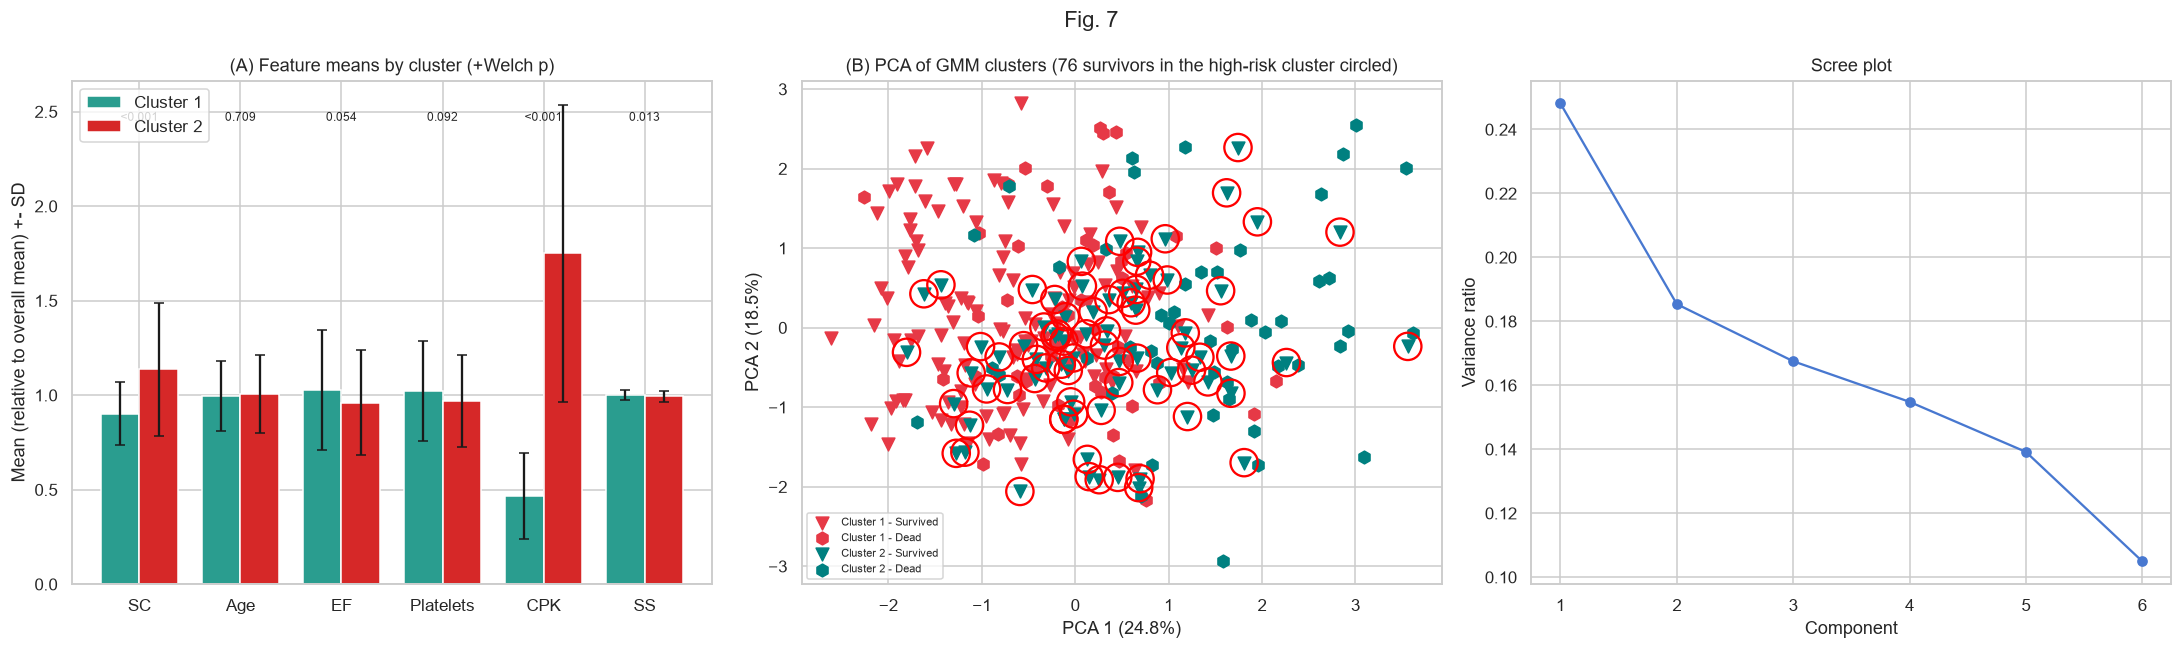

=== TABLE 8 ===


,HR,Z,P,-log2(p)
Age,1.0433,4.6212,0.0000,17.9998
SC,2.2996,2.7531,0.0059,7.4042
CPK,0.9993,-1.6757,0.0938,3.4143
EF,0.9551,-3.9935,0.0001,13.9070
Platelets,1.0000,-0.1280,0.8981,0.1550
SS,0.9656,-1.2900,0.1971,2.3433


The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'ejection_fraction' failed the non-proportional test: p-value is 0.0502.

   Advice 1: the functional form of the variable 'ejection_fraction' might be incorrect. That is,
there may be non-linear terms missing. The proportional hazard test used is very sensitive to
incorrect functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'ejection_fraction' using pd.cut, and then specify it in
`strata=['ejection_fraction', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


---
[A]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html
[B]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Bin-variable-and-stratify-on-it
[C]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Prop

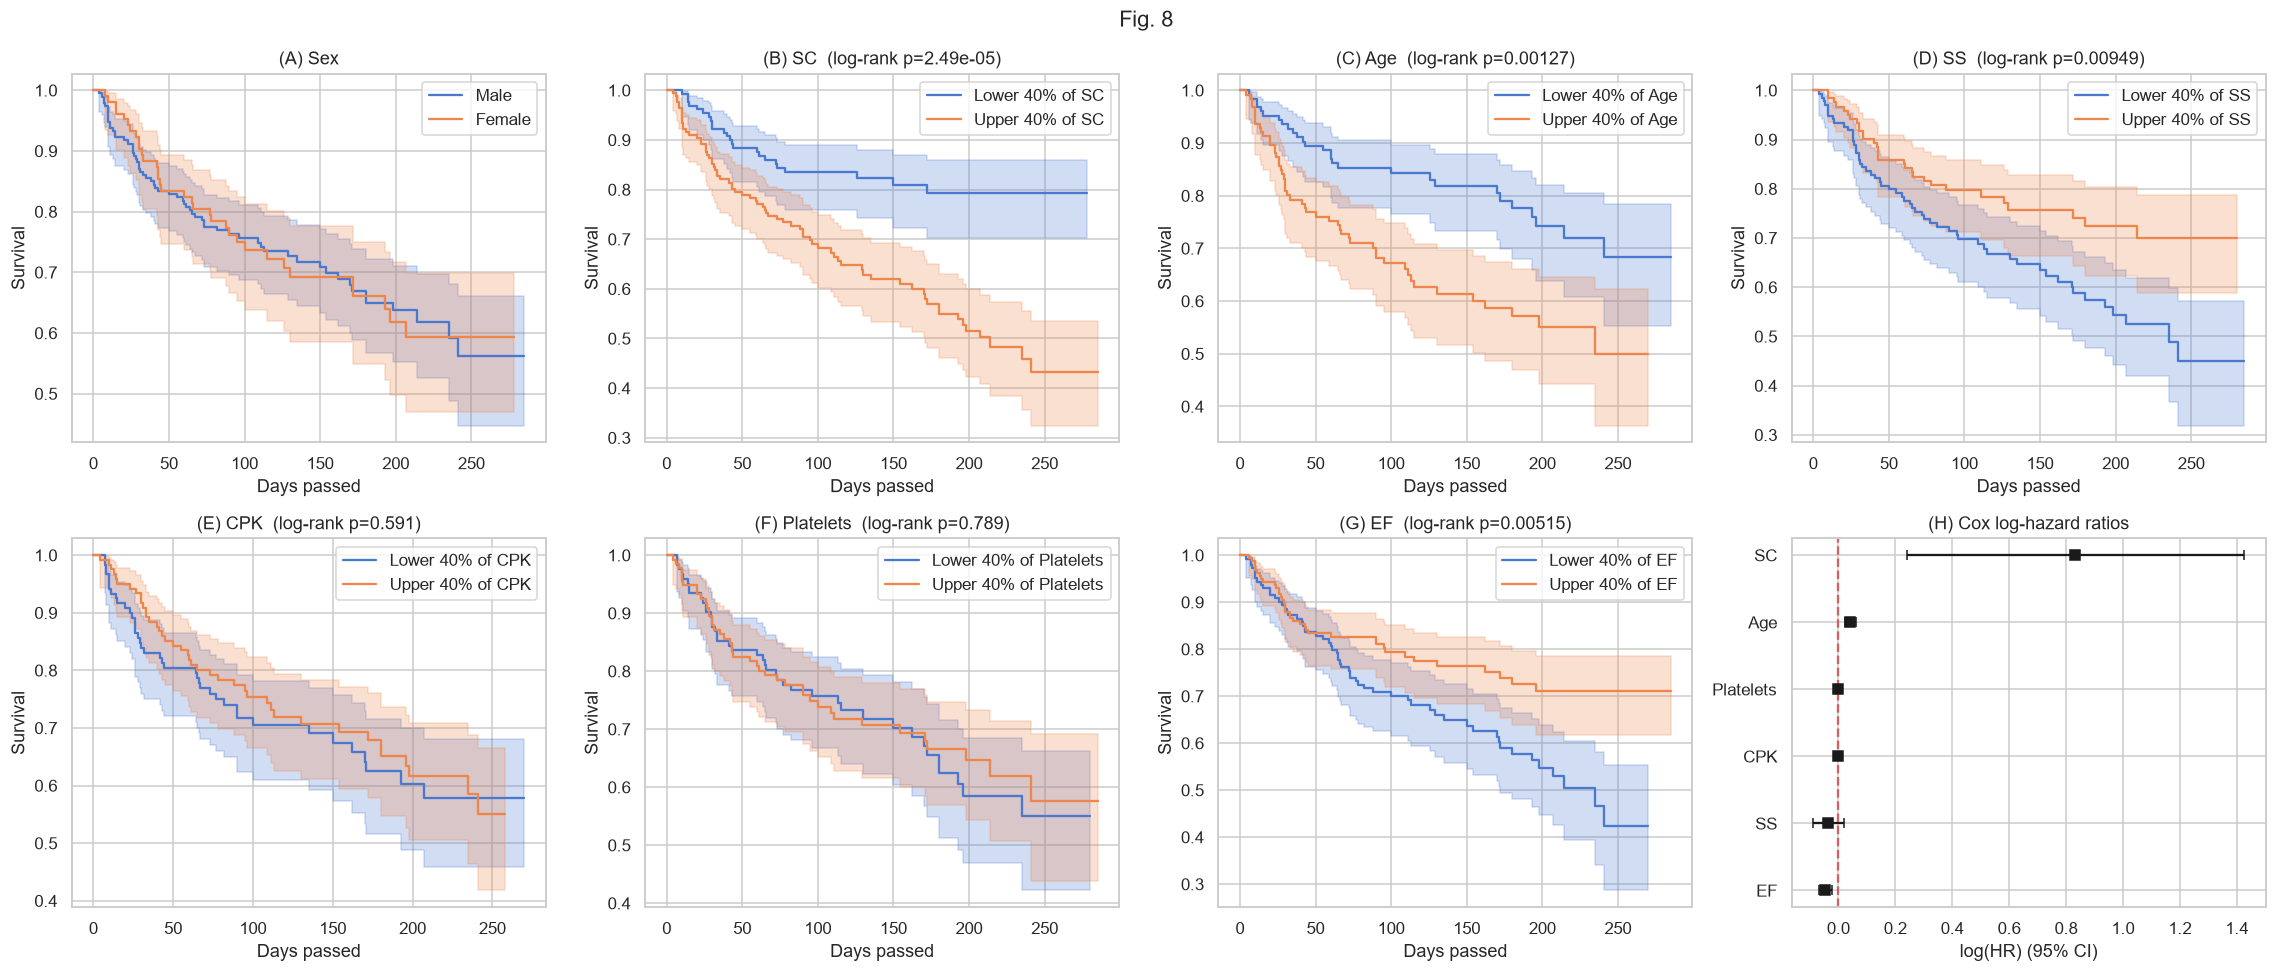


=== 5-fold CV, time excluded (positive class = death) ===


,Model,Acc%,Prec%,Rec%,F1%,AUROC
0,RF,72.92 +- 6.42,58.14 +- 9.19,60.47 +- 8.84,59.03 +- 8.39,0.76 +- 0.06
1,GB,71.92 +- 3.91,55.96 +- 5.19,58.47 +- 11.27,56.81 +- 7.44,0.73 +- 0.06
2,XGB,71.57 +- 6.15,56.07 +- 9.82,55.42 +- 14.85,55.02 +- 10.66,0.73 +- 0.06
3,DT,72.25 +- 7.09,56.80 +- 9.62,58.42 +- 14.55,57.10 +- 11.10,0.67 +- 0.06



=== 5-fold CV, time INCLUDED (positive class = death) ===


,Model,Acc%,Prec%,Rec%,F1%,AUROC
0,RF,84.94 +- 1.88,76.33 +- 3.14,77.00 +- 5.59,76.55 +- 3.54,0.90 +- 0.02
1,GB,81.59 +- 2.74,69.47 +- 3.43,76.00 +- 9.84,72.32 +- 5.69,0.89 +- 0.02
2,XGB,82.94 +- 1.32,72.30 +- 1.38,76.05 +- 4.11,74.07 +- 2.24,0.89 +- 0.01
3,DT,78.60 +- 3.03,66.01 +- 4.54,69.89 +- 12.27,67.30 +- 5.93,0.74 +- 0.06


In [1]:
# %% [markdown]
# # Ali et al. (2023), Healthcare Analytics 3:100182 - Full implementation
# "A machine learning approach for risk factors analysis and survival prediction of HF patients"
#
# Works as a plain script (python file.py) or cell-by-cell in VS Code / Jupyter / Colab.
# Needs: heart_failure_clinical_records_dataset.csv (Kaggle, 299 rows)
# pip install pandas numpy scipy seaborn matplotlib scikit-learn imbalanced-learn xgboost lifelines

# %%
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, log_loss,
                             roc_auc_score, roc_curve, precision_recall_curve, auc,
                             average_precision_score, mutual_info_score)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import logrank_test

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110

try:
    display  # noqa  (Jupyter)
except NameError:
    def display(x):
        print(x.to_string() if hasattr(x, "to_string") else x)

# ----------------------------- CONFIG ---------------------------------------
candidates = ["heart_failure_clinical_records_dataset.csv", "../data/heart_failure_clinical_records_dataset.csv", "../../data/heart_failure_clinical_records_dataset.csv"]
CSV_PATH = next((p for p in candidates if os.path.exists(p)), "heart_failure_clinical_records_dataset.csv")
SEED = 42
# Outliers: "replace" (median-impute, keeps N=299 like Table 2), "remove" (drop rows), "none"
OUTLIER_MODE = "replace"
# The paper's Table 5 excludes 'time' from the classifiers. Set True to test its effect.
INCLUDE_TIME_IN_ML = False
CONT_COLS = ["age", "creatinine_phosphokinase", "ejection_fraction",
             "platelets", "serum_creatinine", "serum_sodium", "time"]
SHORT = {"serum_creatinine": "SC", "creatinine_phosphokinase": "CPK", "ejection_fraction": "EF",
         "serum_sodium": "SS", "high_blood_pressure": "HBP", "age": "Age", "platelets": "Platelets",
         "sex": "Sex", "smoking": "Smoking", "anaemia": "Anaemia", "diabetes": "Diabetes",
         "time": "Time", "DEATH_EVENT": "Target"}
SHOW = os.environ.get("MPLBACKEND", "") != "Agg"
def show():
    if SHOW: plt.show()
    else: plt.close("all")

# %% [markdown]
# ## 1. Data (Section 2.1, Table 1)
# %%
df = pd.read_csv(CSV_PATH)
print(df.shape, "missing:", int(df.isnull().sum().sum()))
print(df["DEATH_EVENT"].value_counts().rename({0: "Survived", 1: "Dead"}))

# %% [markdown]
# ## 2. Table 2 - descriptive statistics
# NOTE: the paper's printed p-values (e.g. Sex <0.001, Diabetes <0.001) are inconsistent with its own
# Fig. 2 (Sex 0.7, Diabetes 0.16) and cannot be reproduced; we report standard tests.
# %%
dead, surv = df[df.DEATH_EVENT == 1], df[df.DEATH_EVENT == 0]
rows = []
for col in ["sex", "smoking", "anaemia", "diabetes", "high_blood_pressure"]:
    p = stats.chi2_contingency(pd.crosstab(df[col], df.DEATH_EVENT))[1]
    for v in (1, 0):
        lab = ("Male" if v else "Female") if col == "sex" else ("Yes" if v else "No")
        n, nd, ns = (df[col] == v).sum(), (dead[col] == v).sum(), (surv[col] == v).sum()
        rows.append([SHORT[col], lab, f"{n} ({n/len(df)*100:.2f})",
                     f"{nd} ({nd/len(dead)*100:.2f})", f"{ns} ({ns/len(surv)*100:.2f})", f"{p:.4f}"])
print("=== TABLE 2 (categorical) ===")
display(pd.DataFrame(rows, columns=["Feature", "Category", "All N=299 (%)", "Dead 96 (%)", "Survived 203 (%)", "P (chi2)"]))

def ms(s): return f"{s.mean():.2f} ({s.std():.2f})"
def mi(s): return f"{s.median():.1f} ({s.quantile(.25):.1f}-{s.quantile(.75):.1f})"
rows = []
for col in CONT_COLS:
    p = stats.mannwhitneyu(dead[col], surv[col]).pvalue
    rows.append([SHORT[col], ms(df[col]), mi(df[col]), ms(dead[col]), mi(dead[col]),
                 ms(surv[col]), mi(surv[col]), f"{p:.2e}"])
print("=== TABLE 2 (numeric) ===")
display(pd.DataFrame(rows, columns=["Feature", "All mean(SD)", "All med(IQR)", "Dead mean(SD)", "Dead med(IQR)",
                                    "Surv mean(SD)", "Surv med(IQR)", "P (Mann-Whitney)"]))

# %% [markdown]
# ## 3. Fig. 2 - clustermap of PAIRWISE P-VALUES (not correlation coefficients, as in the paper)
# %%
cols = ["platelets", "smoking", "serum_sodium", "sex", "diabetes", "ejection_fraction", "anaemia",
        "serum_creatinine", "age", "high_blood_pressure", "time", "creatinine_phosphokinase", "DEATH_EVENT"]
P = pd.DataFrame(0.0, index=cols, columns=cols)
for a in cols:
    for b in cols:
        if a != b:
            P.loc[a, b] = stats.pearsonr(df[a], df[b])[1]
P = P.rename(index=SHORT, columns=SHORT)
g = sns.clustermap(P, cmap="vlag", annot=True, fmt=".2g", annot_kws={"size": 6}, figsize=(11, 9),
                   vmin=0, vmax=1, center=0.5)
g.fig.suptitle("Fig. 2: pairwise Pearson p-values with hierarchical clustering", y=1.01)
show()

# %% [markdown]
# ## 4. Pre-processing (Section 2.2, Fig. 3) and Fig. 4
# %%
def treat_outliers(data, mode):
    d = data.copy()
    if mode == "none":
        return d
    keep = pd.Series(True, index=d.index)
    for c in CONT_COLS:
        q1, q3 = d[c].quantile(.25), d[c].quantile(.75)
        lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
        bad = (d[c] < lo) | (d[c] > hi)
        if mode == "replace":
            d.loc[bad, c] = d.loc[~bad, c].median()
        else:
            keep &= ~bad
    return d[keep].reset_index(drop=True)

df_clean = treat_outliers(df, OUTLIER_MODE)
print(f"Outlier mode '{OUTLIER_MODE}': {len(df)} -> {len(df_clean)} rows")

fig, ax = plt.subplots(2, 7, figsize=(20, 7))
for i, c in enumerate(CONT_COLS):
    sns.boxplot(y=df[c], ax=ax[0, i], color="#f39c12"); ax[0, i].set_title(f"{SHORT[c]} (A)")
    sns.boxplot(y=df_clean[c], ax=ax[1, i], color="#f39c12"); ax[1, i].set_title(f"{SHORT[c]} (B)")
plt.suptitle("Fig. 3: (A) before and (B) after outlier handling"); plt.tight_layout(); show()

lab = df_clean.assign(Target=df_clean.DEATH_EVENT.map({0: "Survived", 1: "Death"}))
fig, ax = plt.subplots(3, 2, figsize=(11, 12))
for a, c in zip(ax.ravel(), CONT_COLS[:6]):
    sns.kdeplot(data=lab, x=c, hue="Target", multiple="stack", fill=True, ax=a, common_norm=True)
    a.set_title(SHORT[c])
plt.suptitle("Fig. 4: stacked KDE by outcome"); plt.tight_layout(); show()

# %% [markdown]
# ## 5. Supervised ML (Section 2.4, Table 3, Table 4, Fig. 5)
# Two evaluation schemes are run side by side:
#  A) "paper_text": SMOTE on the whole dataset, THEN 70/30 split (what Section 2.2/2.4 describe)
#  B) "leak_free" : 70/30 split, SMOTE on the training part only
# %%
ml_cols = [c for c in df_clean.columns if c != "DEATH_EVENT" and (INCLUDE_TIME_IN_ML or c != "time")]
feat_names = ml_cols

def make_split(scheme):
    X, y = df_clean[ml_cols], df_clean["DEATH_EVENT"]
    if scheme == "paper_text":
        Xr, yr = SMOTE(random_state=SEED).fit_resample(X, y)
        return train_test_split(Xr, yr, test_size=0.30, random_state=SEED, stratify=yr)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.30, random_state=SEED, stratify=y)
    Xtr, ytr = SMOTE(random_state=SEED).fit_resample(Xtr, ytr)
    return Xtr, Xte, ytr, yte

def get_models():
    return {  # Table 3
        "DTR": DecisionTreeRegressor(criterion="squared_error", splitter="best", random_state=SEED),
        "XGB": XGBClassifier(learning_rate=0.59, eval_metric="logloss", random_state=SEED),
        "DT": DecisionTreeClassifier(criterion="gini", max_depth=5, random_state=SEED),
        "GB": GradientBoostingClassifier(n_estimators=100, random_state=SEED),
        "RF": RandomForestClassifier(n_estimators=65, max_depth=8, random_state=SEED),
    }

def evaluate(scheme):
    Xtr, Xte, ytr, yte = make_split(scheme)
    out, curves, fitted = [], {}, {}
    for name, m in get_models().items():
        m.fit(Xtr, ytr); fitted[name] = m
        if name == "DTR":
            raw = m.predict(Xte); pred = (raw >= .5).astype(int); prob = np.clip(raw, 0, 1)
            acc_paper = m.score(Xte, yte) * 100          # R^2 (what the paper put in the Accuracy column)
        else:
            pred = m.predict(Xte); prob = m.predict_proba(Xte)[:, 1]
            acc_paper = accuracy_score(yte, pred) * 100
        fpr, tpr, _ = roc_curve(yte, prob)
        pr, rc, _ = precision_recall_curve(yte, prob)
        curves[name] = (fpr, tpr, auc(fpr, tpr), rc, pr, auc(rc, pr))
        out.append({"Algorithm": name,
                    "Acc% (paper-style)": round(acc_paper, 2),
                    "Acc% (true)": round(accuracy_score(yte, pred) * 100, 2),
                    "Precision%": round(precision_score(yte, pred, average="weighted", zero_division=0) * 100, 2),
                    "Recall%": round(recall_score(yte, pred, average="weighted", zero_division=0) * 100, 2),
                    "F1%": round(f1_score(yte, pred, average="weighted", zero_division=0) * 100, 2),
                    "LogLoss (hard labels, paper)": round(log_loss(yte, pred), 3),
                    "LogLoss (probabilities)": round(log_loss(yte, prob), 3),
                    "AUROC": round(curves[name][2], 3), "AUPRC": round(curves[name][5], 3)})
    print(f"   test size = {len(yte)}")
    return pd.DataFrame(out), curves, fitted, (Xtr, ytr)

results, store = {}, {}
for scheme in ["paper_text", "leak_free"]:
    print(f"\n=== TABLE 4 - scheme: {scheme} ===")
    res, curves, fitted, tr = evaluate(scheme)
    display(res); results[scheme], store[scheme] = res, (curves, fitted, tr)

curves, trained, (X_train_ref, y_train_ref) = store["paper_text"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 6))
for n, (fpr, tpr, ra, rc, pr, pa) in curves.items():
    a1.plot(fpr, tpr, label=f"{n} (AUC={ra:.3f})"); a2.plot(rc, pr, label=f"{n} (AUC={pa:.3f})")
a1.plot([0, 1], [0, 1], "--", c="orange"); a1.set(xlabel="FPR", ylabel="TPR", title="(A) ROC"); a1.legend()
a2.set(xlabel="Recall", ylabel="Precision", title="(B) Precision-Recall"); a2.legend()
plt.suptitle("Fig. 5 (paper_text scheme)"); plt.tight_layout(); show()

# %% [markdown]
# ## 6. Risk factors (Section 2.6, Tables 5-7, Fig. 6)
# %%
imp = pd.DataFrame({n: m.feature_importances_ for n, m in trained.items()}, index=feat_names)
imp.index = [SHORT[i] for i in imp.index]
print("=== TABLE 5 ==="); display(imp.round(4))
t6 = [[n] + imp[n].sort_values(ascending=False).index[:6].tolist() for n in imp.columns]
print("=== TABLE 6 ==="); display(pd.DataFrame(t6, columns=["Algorithm", "1st", "2nd", "3rd", "4th", "5th", "6th"]))

fig, ax = plt.subplots(3, 2, figsize=(13, 14)); ax = ax.ravel()
for a, n in zip(ax, ["DTR", "XGB", "DT", "GB", "RF"]):
    s = imp[n].sort_values(ascending=False)
    sns.barplot(x=s.values, y=s.index, ax=a, palette="Paired"); a.set_title(n); a.set_xlabel("Feature importance score")
ax[-1].axis("off"); plt.suptitle("Fig. 6"); plt.tight_layout(); show()

# Table 7: Weka's CFSSE / GRAE / IGAE / RFAE are re-implemented approximately (Weka discretises with MDL).
Xf = df_clean[ml_cols].copy(); yf = df_clean["DEATH_EVENT"].values
def disc(s, bins=10):
    return s.astype(int).values if s.nunique() <= 2 else pd.qcut(s, bins, duplicates="drop", labels=False).values
def entropy(a):
    p = np.bincount(a) / len(a); p = p[p > 0]; return -(p * np.log2(p)).sum()
def relieff(X, y, k=10):
    Xs = MinMaxScaler().fit_transform(X); w = np.zeros(Xs.shape[1]); n = len(Xs)
    for i in range(n):
        d = np.abs(Xs - Xs[i]).sum(1); d[i] = np.inf
        hit = np.argsort(np.where(y == y[i], d, np.inf))[:k]; miss = np.argsort(np.where(y != y[i], d, np.inf))[:k]
        w += (np.abs(Xs[miss] - Xs[i]).mean(0) - np.abs(Xs[hit] - Xs[i]).mean(0)) / n
    return w
ig, gr = {}, {}
for c in Xf.columns:
    d = disc(Xf[c]); ig[c] = mutual_info_score(d, yf) / np.log(2); h = entropy(d); gr[c] = ig[c] / h if h > 0 else 0
cfs = {c: abs(np.corrcoef(Xf[c], yf)[0, 1]) for c in Xf.columns}   # per-feature correlation merit (approx. of CFS)
rw = dict(zip(Xf.columns, relieff(Xf.values, yf)))
t7 = pd.DataFrame({"CFSSE~": cfs, "GRAE~": gr, "IGAE~": ig, "RFAE~": rw}); t7.index = [SHORT[i] for i in t7.index]
print("=== TABLE 7 (approximate Weka equivalents) ==="); display(t7.round(4))

# %% [markdown]
# ## 7. Unsupervised ML - GMM + PCA (Sections 2.7-2.8, Fig. 7)
# %%
top6 = ["serum_creatinine", "age", "ejection_fraction", "platelets", "creatinine_phosphokinase", "serum_sodium"]
Xt = df_clean[top6]; Z = StandardScaler().fit_transform(Xt)
cl = GaussianMixture(n_components=2, covariance_type="full", random_state=SEED).fit_predict(Z)
# label clusters so Cluster 1 = lower-mortality ("survived") cluster
if df_clean.DEATH_EVENT[cl == 0].mean() > df_clean.DEATH_EVENT[cl == 1].mean(): cl = 1 - cl
print(pd.crosstab(pd.Series(cl + 1, name="GMM cluster"), df_clean.DEATH_EVENT.map({0: "Survived", 1: "Dead"})))

pca = PCA(n_components=2, random_state=SEED); Zp = pca.fit_transform(Z)
full = PCA().fit(Z)
fig, ax = plt.subplots(1, 3, figsize=(20, 6))
# (A) mean +- SD with Welch p-values
x = np.arange(len(top6)); w = .38
for k, (colr, nm) in enumerate([("#2a9d8f", "Cluster 1"), ("#d62828", "Cluster 2")]):
    sub = Xt[cl == k]
    ax[0].bar(x + (k - .5) * w, sub.mean() / Xt.mean(), w, yerr=sub.std() / Xt.mean(), color=colr, label=nm, capsize=3)
for i, c in enumerate(top6):
    p = stats.ttest_ind(Xt[c][cl == 0], Xt[c][cl == 1], equal_var=False)[1]
    ax[0].text(i, ax[0].get_ylim()[1] * .92, "<0.001" if p < .001 else f"{p:.3f}", ha="center", fontsize=8)
ax[0].set_xticks(x); ax[0].set_xticklabels([SHORT[c] for c in top6]); ax[0].set_ylabel("Mean (relative to overall mean) +- SD")
ax[0].set_title("(A) Feature means by cluster (+Welch p)"); ax[0].legend()
# (B) PCA scatter + circle survivors sitting in the 'dead' cluster
status = df_clean.DEATH_EVENT.values
for k, colr in [(0, "#e63946"), (1, "#008080")]:
    for s, mk in [(0, "v"), (1, "h")]:
        m = (cl == k) & (status == s)
        ax[1].scatter(Zp[m, 0], Zp[m, 1], c=colr, marker=mk, s=70, label=f"Cluster {k+1} - {'Survived' if s==0 else 'Dead'}")
mis = (cl == 1) & (status == 0)
ax[1].scatter(Zp[mis, 0], Zp[mis, 1], s=320, facecolors="none", edgecolors="red", linewidths=1.5)
ax[1].set_xlabel(f"PCA 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"); ax[1].set_ylabel(f"PCA 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
ax[1].set_title(f"(B) PCA of GMM clusters ({mis.sum()} survivors in the high-risk cluster circled)"); ax[1].legend(fontsize=7)
# scree (Fig. 1 'PCA' block)
ax[2].plot(range(1, 7), full.explained_variance_ratio_, "o-"); ax[2].set(title="Scree plot", xlabel="Component", ylabel="Variance ratio")
plt.suptitle("Fig. 7"); plt.tight_layout(); show()

# %% [markdown]
# ## 8. Survival analysis (Section 2.9, Table 8, Fig. 8) - on the ORIGINAL (not SMOTE'd) records
# %%
surv_feats = ["age", "serum_creatinine", "creatinine_phosphokinase", "ejection_fraction", "platelets", "serum_sodium"]
cph = CoxPHFitter().fit(df_clean[surv_feats + ["time", "DEATH_EVENT"]], duration_col="time", event_col="DEATH_EVENT")
t8 = cph.summary[["exp(coef)", "z", "p", "-log2(p)"]].rename(columns={"exp(coef)": "HR", "z": "Z", "p": "P"})
t8.index = [SHORT[i] for i in t8.index]
print("=== TABLE 8 ==="); display(t8.round(4))
try: cph.check_assumptions(df_clean[surv_feats + ["time", "DEATH_EVENT"]], p_value_threshold=.05, show_plots=False)
except Exception as e: print("PH check skipped:", e)

kmf = KaplanMeierFitter()
fig, ax = plt.subplots(2, 4, figsize=(21, 9)); ax = ax.ravel()
def km(a, mask, label):
    kmf.fit(df_clean.time[mask], df_clean.DEATH_EVENT[mask], label=label); kmf.plot_survival_function(ax=a, ci_show=True)
km(ax[0], df_clean.sex == 1, "Male"); km(ax[0], df_clean.sex == 0, "Female"); ax[0].set_title("(A) Sex")
for a, (c, t) in zip(ax[1:7], [("serum_creatinine", "(B) SC"), ("age", "(C) Age"), ("serum_sodium", "(D) SS"),
                                ("creatinine_phosphokinase", "(E) CPK"), ("platelets", "(F) Platelets"), ("ejection_fraction", "(G) EF")]):
    lo, hi = df_clean[c] <= df_clean[c].quantile(.4), df_clean[c] >= df_clean[c].quantile(.6)
    km(a, lo, f"Lower 40% of {SHORT[c]}"); km(a, hi, f"Upper 40% of {SHORT[c]}")
    p = logrank_test(df_clean.time[lo], df_clean.time[hi], df_clean.DEATH_EVENT[lo], df_clean.DEATH_EVENT[hi]).p_value
    a.set_title(f"{t}  (log-rank p={p:.3g})")
s = cph.summary.sort_values("coef"); yp = np.arange(len(s))
ax[7].errorbar(s["coef"], yp, xerr=[s["coef"] - s["coef lower 95%"], s["coef upper 95%"] - s["coef"]], fmt="s", c="k", capsize=3)
ax[7].axvline(0, ls="--", c="r"); ax[7].set_yticks(yp); ax[7].set_yticklabels([SHORT[i] for i in s.index])
ax[7].set_xlabel("log(HR) (95% CI)"); ax[7].set_title("(H) Cox log-hazard ratios")
for a in ax[:7]: a.set_xlabel("Days passed"); a.set_ylabel("Survival")
plt.suptitle("Fig. 8"); plt.tight_layout(); show()

# %% [markdown]
# ## 9. Honest benchmark - 5-fold stratified CV, all 299 patients, SMOTE inside each training fold only
# %%
def cv_benchmark(use_time):
    cols = [c for c in df.columns if c != "DEATH_EVENT" and (use_time or c != "time")]
    X, y = df[cols], df["DEATH_EVENT"]
    cands = {"RF": RandomForestClassifier(n_estimators=65, max_depth=8, random_state=SEED),
             "GB": GradientBoostingClassifier(n_estimators=100, random_state=SEED),
             "XGB": XGBClassifier(learning_rate=0.59, eval_metric="logloss", random_state=SEED),
             "DT": DecisionTreeClassifier(max_depth=5, random_state=SEED)}
    rows = []
    for n, clf in cands.items():
        pipe = ImbPipeline([("sc", StandardScaler()), ("smote", SMOTE(random_state=SEED)), ("clf", clf)])
        A, P_, R, F, U = [], [], [], [], []
        for tr, va in StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, y):
            pipe.fit(X.iloc[tr], y.iloc[tr]); pr = pipe.predict(X.iloc[va]); pb = pipe.predict_proba(X.iloc[va])[:, 1]
            A.append(accuracy_score(y.iloc[va], pr)); P_.append(precision_score(y.iloc[va], pr, zero_division=0))
            R.append(recall_score(y.iloc[va], pr)); F.append(f1_score(y.iloc[va], pr)); U.append(roc_auc_score(y.iloc[va], pb))
        f = lambda v, k=100: f"{np.mean(v)*k:.2f} +- {np.std(v)*k:.2f}"
        rows.append({"Model": n, "Acc%": f(A), "Prec%": f(P_), "Rec%": f(R), "F1%": f(F), "AUROC": f(U, 1)})
    return pd.DataFrame(rows)

for ut in (False, True):
    print(f"\n=== 5-fold CV, time {'INCLUDED' if ut else 'excluded'} (positive class = death) ===")
    display(cv_benchmark(ut))